# Previsão do Tempo em Macau com Machine Learning
### CSAI3121 – Machine Learning and Intelligent Data Analysis · Group Project

**Equipe:** Thiago Honorato Ferreira (P262742-1) · Marcelo Oliveira (P262739-4) · João Vitor Konrad (P262740-2)

---


---
## 1. Bibliotecas


In [1]:
%%capture
%pip install -q pandas numpy scipy scikit-learn matplotlib seaborn requests joblib
import time, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, brier_score_loss)
import weather_utils as wu
from weather_utils import CLASSES, NUMERIC_COLS, CLASS_COLORS, C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_GRAY
wu.set_plot_style()

---
## 2. Coleta de dados

Quatro passos:

1. **Dados do (Visual Crossing):** análise prévia para ver se servem. Não servem: são só **15 dias**, e são a *previsão* dos próximos dias, não o histórico.
2. **Configuração:** definimos o local, o período a baixar e a divisão treino / validação / teste.
3. **Alternativa – Open‑Meteo:** baixamos 12 anos de histórico diário da [Open‑Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api)
   (reanálise ERA5, gratuita e sem cadastro) e salvamos o arquivo bruto em `data/macao_openmeteo.csv`.
4. **Padronização:** convertemos o Open‑Meteo para o **mesmo formato do arquivo da professora** (mesmos nomes de colunas e unidades métricas),
   para que o resto do notebook funcione igual com qualquer uma das fontes.

| Coluna (formato Visual Crossing) | Significado | Unidade |
|---|---|---|
| `tempmax`, `tempmin`, `temp` | temperatura máx., mín. e média do dia | °C |
| `feelslikemax`, `feelslikemin` | sensação térmica máx./mín. | °C |
| `dew` | ponto de orvalho médio | °C |
| `humidity` | umidade relativa média | % |
| `precip` | precipitação total | mm |
| `precipcover` | % das horas do dia com chuva | % |
| `windspeed`, `windgust` | vento máximo e rajada máxima | km/h |
| `winddir` | direção dominante do vento | graus |
| `sealevelpressure` | pressão ao nível do mar | hPa |
| `cloudcover` | cobertura de nuvens média | % |
| `solarenergy` | energia solar diária | MJ/m² |
| `conditions` | rótulo textual da condição do tempo | texto |

In [2]:
# 2.1 Análise prévia dos dados da professora: só 15 dias de PREVISÃO -> não servem para treinar
DATA_DIR = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data"   # o notebook roda em notebooks/
teacher = pd.read_csv(DATA_DIR / "macao_teacher_data.csv")
wu.check_coverage(teacher, "Visual Crossing (professora)")
teacher[["datetime", "tempmax", "tempmin", "conditions"]].head(3)

Visual Crossing (professora): 15 days | 2026-10-11 -> 2026-10-25 | missing dates: 0 | future dates (forecast): yes | usable for training: NO (needs >= 3000 days)


,datetime,tempmax,tempmin,conditions
0,2026-10-11,84.2,78.7,Partially cloudy
1,2026-10-12,84.9,78.4,Rain
2,2026-10-13,85.7,77.6,Clear


In [3]:
# 2.2 Configuração: o que baixar no lugar dos dados da professora e como dividir
SEED = 42                                                    # random_state de todos os modelos -> resultados reprodutíveis
LOCATION_NAME, LATITUDE, LONGITUDE, TIMEZONE = "Macau", 22.1987, 113.5439, "Asia/Macau"
START_DATE, END_DATE = "2014-01-01", "2025-12-31"            # 12 anos (> 3000 dias exigidos)
TRAIN_END, VAL_END = "2021-12-31", "2023-12-31"              # data do alvo: treino 2014–21 | validação 2022–23 | teste 2024–25
OM_FILE = DATA_DIR / "macao_openmeteo.csv"                   # histórico bruto do Open-Meteo
PROCESSED_DIR, FIG_DIR, RESULTS_DIR, MODELS_DIR = wu.make_dirs(
    DATA_DIR / "processed", *(DATA_DIR.parent / d for d in ("figures", "results", "models")))

def save_fig(name):
    '''Salva a figura atual em figures/<name>.png (para o relatório).'''
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [4]:
# 2.3 Alternativa: baixar o histórico do Open-Meteo (só na 1ª execução) e salvar o CSV bruto em data/
if not OM_FILE.exists():
    wu.download_open_meteo(LATITUDE, LONGITUDE, START_DATE, END_DATE, TIMEZONE).to_csv(OM_FILE, index=False)
om_raw = pd.read_csv(OM_FILE)
wu.check_coverage(om_raw, "Open-Meteo", date_col="time")
om_raw.head(3)

Open-Meteo: 4383 days | 2014-01-01 -> 2025-12-31 | missing dates: 0 | future dates (forecast): no | usable for training: YES


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,dew_point_2m_mean,relative_humidity_2m_mean,precipitation_sum,precipitation_hours,wind_gusts_10m_max,wind_speed_10m_max,wind_direction_10m_dominant,pressure_msl_mean,cloud_cover_mean,shortwave_radiation_sum
0,2014-01-01,18.2,11.4,14.3,16.7,8.8,6.3,60,0.0,0.0,23.8,11.6,43,1019.2,0,16.95
1,2014-01-02,19.6,11.3,15.7,20.5,10.1,12.7,83,0.0,0.0,20.2,10.0,88,1016.6,12,15.90
2,2014-01-03,21.6,15.9,18.3,22.9,15.8,14.1,77,0.0,0.0,21.6,10.5,347,1015.9,34,15.76


In [5]:
# 2.4 Deixar o Open-Meteo no mesmo formato do arquivo da professora
raw_df = wu.to_visual_crossing_schema(om_raw, LOCATION_NAME)   # renomeia colunas, cria precipcover e conditions
DATA_SOURCE = "Open-Meteo (ERA5)"
teacher_m = wu.to_metric(teacher)                               # professora está em °F/mph -> °C/km/h para comparar
same = [c for c in raw_df.columns if c in teacher_m.columns]
print(f"{len(same)} de {len(raw_df.columns)} colunas com o mesmo nome e unidade do arquivo da professora")
pd.DataFrame({"Professora (Visual Crossing)": teacher_m[same].iloc[0], "Open-Meteo convertido": raw_df[same].iloc[0]})  # 1ª linha de cada

18 de 18 colunas com o mesmo nome e unidade do arquivo da professora


,Professora (Visual Crossing),Open-Meteo convertido
name,macao,Macau
datetime,2026-10-11,2014-01-01
tempmax,29.0,18.2
tempmin,25.9,11.4
temp,27.4,14.3
feelslikemax,33.4,16.7
feelslikemin,25.9,8.8
dew,22.7,6.3
humidity,75.5,60
precip,0.0,0.0


---
## 3. Qualidade dos dados

Antes de modelar, um analista **sempre audita os dados**. Em vez de escrever à mão um limite para cada coluna, usamos
**regras físicas por tipo de variável**:

* **Datas** – duplicadas ou faltando (os lags dependem de dias consecutivos);
* **Valores ausentes (NaN)**;
* **Valores impossíveis** – quantidades que só podem ser ≥ 0 (chuva, vento, nuvens, pressão…), percentuais acima de 100 %,
  direção do vento acima de 360°, Tmin maior que Tmax ou temperatura média fora de [Tmin, Tmax];
* **Outliers** – valores extremos. Em meteorologia, extremos geralmente são **reais** (tufões!), então
  nós os **investigamos** em vez de apagá‑los.

Se a auditoria não encontra nenhum problema, **não precisamos de uma etapa de limpeza**: uma função que não remove nada só
complicaria o código. Mantemos apenas um `assert` que interrompe o notebook caso um problema apareça no futuro.

In [6]:
# 3.1 Auditoria de qualidade: regras físicas por tipo de variável (sem limites escritos à mão por coluna)
quality = wu.quality_report(raw_df)
quality

duplicated dates               0
missing dates                  0
missing values (NaN)           0
negative where must be >= 0    0
percent above 100%             0
wind direction above 360°      0
Tmin above Tmax                0
Tmean outside [Tmin, Tmax]     0
Name: count, dtype: int64

In [7]:
# 3.2 A auditoria não encontrou nenhum problema, então não há o que limpar: só indexamos por data.
#  O assert garante isso: se um dia os dados mudarem e surgir um problema, o notebook para aqui.
assert quality.sum() == 0, "A auditoria encontrou problemas: trate-os antes de continuar."
df = raw_df.set_index(pd.to_datetime(raw_df["datetime"]).rename("date"))[NUMERIC_COLS + ["conditions"]]
df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,humidity,precip,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,solarenergy,conditions
date,,,,,,,,,,,,,,,,
2014-01-01,18.2,11.4,14.3,16.7,8.8,6.3,60,0.0,0.0,23.8,11.6,43,1019.2,0,16.95,Clear
2014-01-02,19.6,11.3,15.7,20.5,10.1,12.7,83,0.0,0.0,20.2,10.0,88,1016.6,12,15.90,Clear
2014-01-03,21.6,15.9,18.3,22.9,15.8,14.1,77,0.0,0.0,21.6,10.5,347,1015.9,34,15.76,Partially cloudy
2014-01-04,20.4,14.6,17.1,17.6,11.4,8.9,59,0.0,0.0,39.2,22.4,1,1018.1,1,16.59,Clear
2014-01-05,18.6,13.3,15.8,17.2,10.1,7.9,60,0.0,0.0,32.0,16.5,69,1018.5,1,16.75,Clear


In [8]:
# 3.3 Outliers extremos (3 x IQR): investigar, não apagar
display(wu.iqr_outliers(df, ["tempmax", "tempmin", "precip", "windgust", "sealevelpressure"]))
print("Top 5 dias com maior rajada de vento (conferir com tufões conhecidos):")
df.nlargest(5, "windgust")[["windgust", "sealevelpressure", "precip", "conditions"]]

,lower,upper,n_outliers
tempmax,-0.0,51.8,0
tempmin,-9.6,52.7,0
precip,-15.3,20.4,324
windgust,-8.2,85.6,23
sealevelpressure,977.3,1048.0,0


Top 5 dias com maior rajada de vento (conferir com tufões conhecidos):


,windgust,sealevelpressure,precip,conditions
date,,,,
2018-09-16,173.2,987.4,121.7,"Rain, Overcast"
2017-08-23,151.2,993.3,66.4,"Rain, Overcast"
2025-09-24,149.8,990.6,85.2,"Rain, Overcast"
2023-09-02,140.4,997.0,115.2,"Rain, Overcast"
2025-07-20,135.4,985.9,69.1,"Rain, Overcast"


**Interpretação.** Os outliers extremos aparecem quase só em **precipitação** e **rajada de vento** – distribuições
naturalmente assimétricas (muitos dias secos/calmos e poucos dias de tempestade). Os dias de rajada máxima
coincidem com **tufões reais** que atingiram Macau – **Mangkhut (16/09/2018)**, **Hato (23/08/2017)**, **Ragasa (24/09/2025)**,
**Saola (02/09/2023)** e **Wipha (20/07/2025)** – com a pressão despencando e chuva > 60 mm no mesmo dia. Portanto **não removemos esses valores**: eles são
eventos verdadeiros e importantes. Modelos baseados em árvores são robustos a eles, e nos modelos lineares
usamos padronização (e regularização Ridge), que reduzem sua influência.

---
## 4. Mapeamento das condições do tempo → 4 classes

A especificação exige **documentar um mapeamento claro** dos rótulos originais para um conjunto pequeno de classes.
O Visual Crossing produz rótulos combinados como `"Rain, Partially cloudy"` ou `"Snow, Rain, Overcast"`.
Nossa regra (em ordem de prioridade):

| Rótulo original contém… | Classe final | Justificativa |
|---|---|---|
| `Rain`, `Snow`, `Freezing`, `Drizzle`, `Thunderstorm`, `Hail` | **Rain** | qualquer precipitação domina a percepção do dia (leva guarda‑chuva?) |
| `Overcast` | **Cloudy** | céu encoberto, sem chuva |
| `Partially cloudy` | **Partly Cloudy** | céu parcialmente nublado |
| `Clear` | **Clear** | céu limpo |

A prioridade importa: `"Rain, Overcast"` → **Rain** (a chuva é mais relevante que as nuvens).

> ℹ No caso do Open‑Meteo, o rótulo no estilo VC foi gerado por `make_vc_style_conditions` com limiares
> explícitos: chuva ≥ **1 mm** (convenção da OMM para "dia de chuva" – evita contar garoa desprezível),
> nuvens ≥ **70 %** = encoberto, **30–70 %** = parcialmente nublado, < **30 %** = limpo (≈ escala de *oktas*).

In [9]:
# 4.1 Rótulo original -> 4 classes (prioridade da tabela acima)
df["cond_class"] = wu.to_class(df["conditions"])
print("Rótulos sem mapeamento:", df["cond_class"].isna().sum())
pd.crosstab(df["conditions"], df["cond_class"])[CLASSES]   # auditoria: qual rótulo caiu em qual classe

Rótulos sem mapeamento: 0


cond_class,Clear,Partly Cloudy,Cloudy,Rain
conditions,,,,
Clear,683,0,0,0
Overcast,0,0,687,0
Partially cloudy,0,909,0,0
"Rain, Clear",0,0,0,62
"Rain, Overcast",0,0,0,1581
"Rain, Partially cloudy",0,0,0,461


---
## 5. Análise Exploratória de Dados (EDA)

Objetivos da EDA (exigidos na especificação):
1. Estatísticas resumo e **distribuições** das variáveis principais;
2. **Séries temporais**: tendências, sazonalidade e observações incomuns;
3. **Relações** entre features e alvos (inclui autocorrelação – a base dos lags);
4. Problemas de qualidade, **desbalanceamento de classes** e outliers.

In [10]:
# 5.1 Estatísticas resumo
df[NUMERIC_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tempmax,4383.0,25.70,4.77,6.50,22.2,26.70,29.60,36.10
tempmin,4383.0,21.33,5.40,3.60,17.1,22.60,26.00,29.50
temp,4383.0,23.34,5.01,4.90,19.4,24.50,27.70,31.50
feelslikemax,4383.0,28.55,7.94,-0.90,22.6,29.70,35.30,44.00
feelslikemin,4383.0,23.02,8.51,-3.90,16.3,24.70,30.70,35.60
dew,4383.0,19.67,6.41,-5.80,15.4,21.50,25.20,27.70
humidity,4383.0,80.85,10.53,32.00,76.0,84.00,88.00,97.00
precip,4383.0,5.50,12.43,0.00,0.0,0.80,5.10,195.80
precipcover,4383.0,27.26,29.79,0.00,0.0,16.67,45.83,100.00
windgust,4383.0,39.47,11.11,13.00,32.0,38.20,45.40,173.20


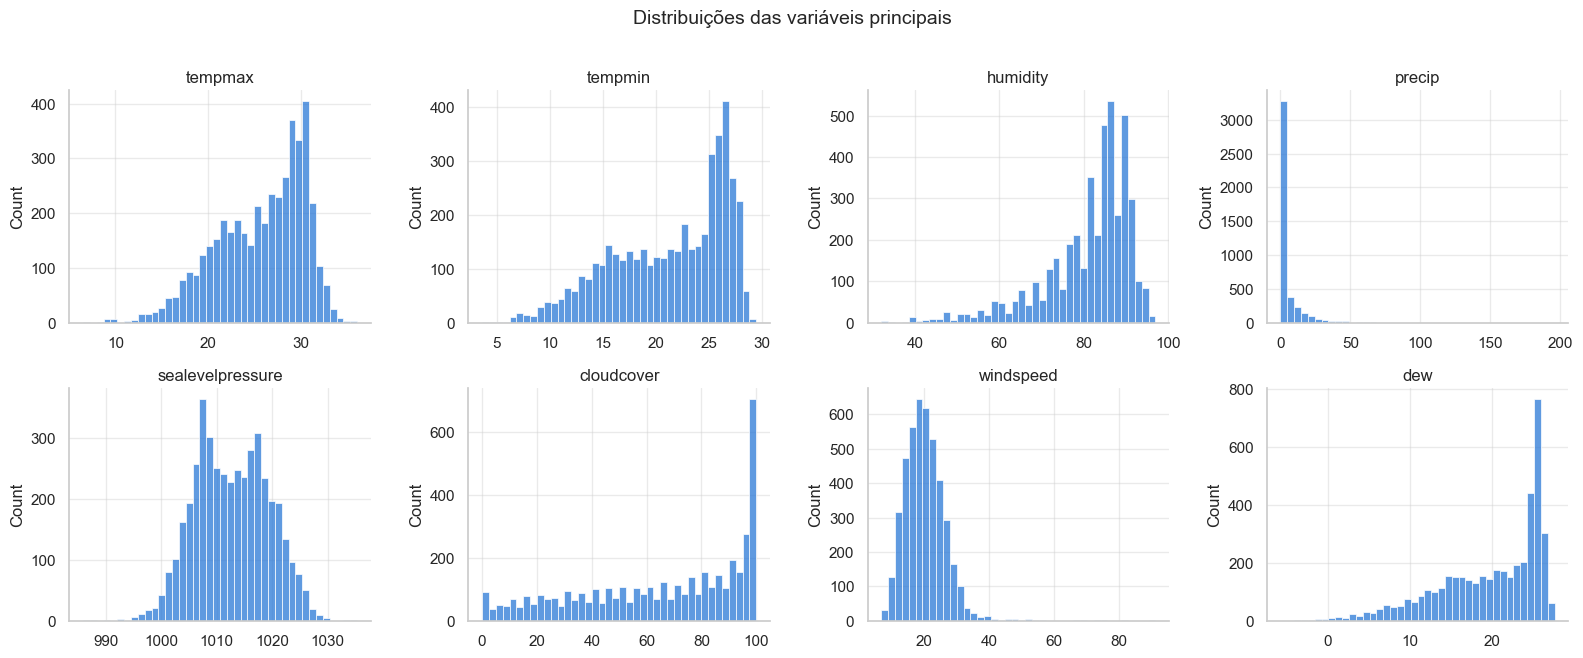

In [11]:
# ---------------------------------------------------------------
# 5.2 Distribuições das variáveis principais
# ---------------------------------------------------------------
key_vars = ["tempmax", "tempmin", "humidity", "precip", "sealevelpressure", "cloudcover", "windspeed", "dew"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), key_vars):
    sns.histplot(df[col], bins=40, ax=ax, color=C_BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distribuições das variáveis principais", fontsize=14, y=1.01)
plt.tight_layout(); save_fig("eda_distributions"); plt.show()

**O que observar:** as temperaturas são **bimodais/assimétricas à esquerda** (verão longo e quente ~28–32 °C, inverno curto e ameno);
a **precipitação** é muito assimétrica (muitos dias com ~0 mm e poucos com > 50 mm); a **umidade** é alta quase sempre (clima subtropical úmido);
a **pressão** é mais alta no inverno (monção de nordeste/anticiclone siberiano) e mais baixa no verão.

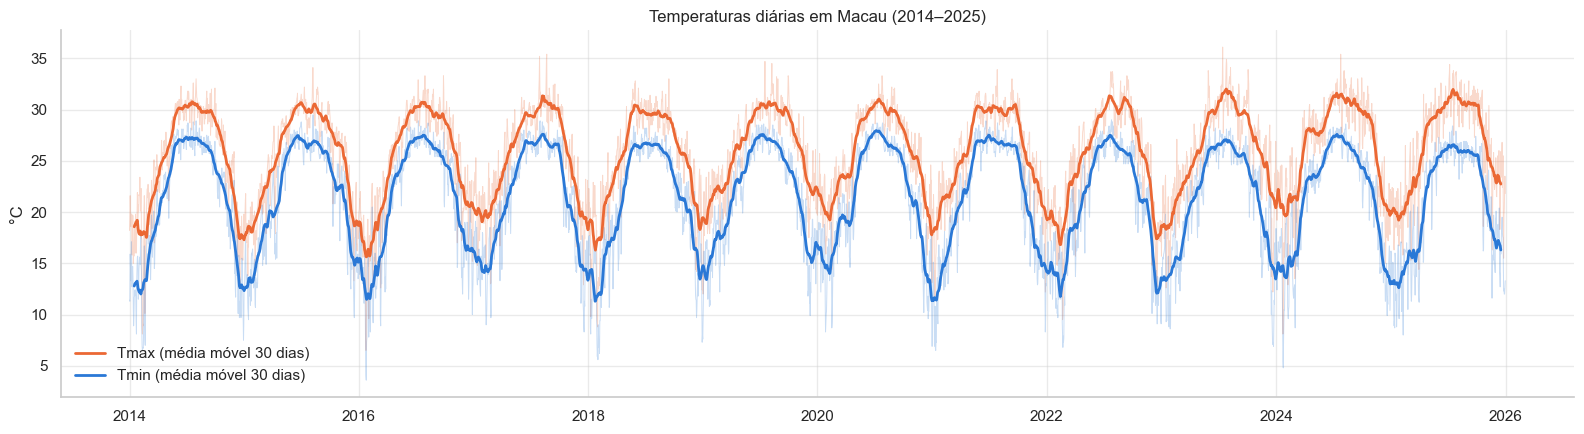

In [12]:
# ---------------------------------------------------------------
# 5.3 Série temporal das temperaturas (tendência e sazonalidade)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(df.index, df["tempmax"], color=C_ORANGE, alpha=0.25, lw=0.7)
ax.plot(df.index, df["tempmin"], color=C_BLUE, alpha=0.25, lw=0.7)
ax.plot(df.index, df["tempmax"].rolling(30, center=True).mean(), color=C_ORANGE, lw=2, label="Tmax (média móvel 30 dias)")
ax.plot(df.index, df["tempmin"].rolling(30, center=True).mean(), color=C_BLUE, lw=2, label="Tmin (média móvel 30 dias)")
ax.set_ylabel("°C"); ax.set_title(f"Temperaturas diárias em {LOCATION_NAME} ({START_DATE[:4]}–{END_DATE[:4]})")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout(); save_fig("eda_timeseries_temp"); plt.show()

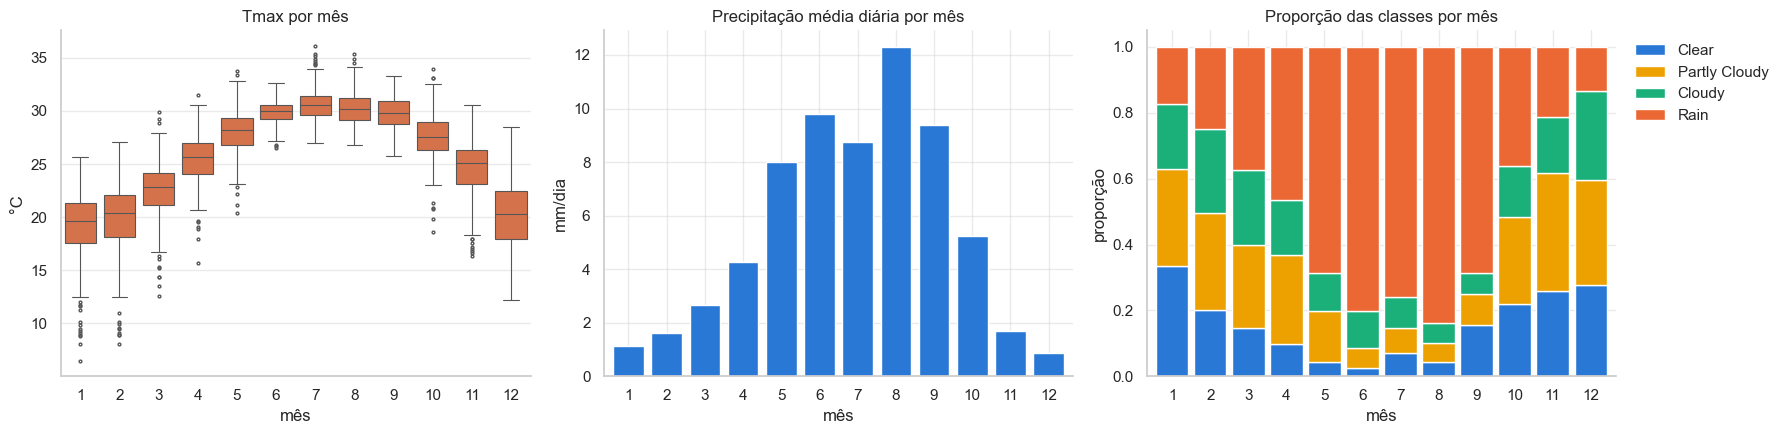

In [13]:
# ---------------------------------------------------------------
# 5.4 Sazonalidade mensal: temperatura, chuva e classes
# ---------------------------------------------------------------
tmp = df.assign(month=df.index.month)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# (a) Boxplot mensal de Tmax
sns.boxplot(data=tmp, x="month", y="tempmax", ax=axes[0], color=C_ORANGE, fliersize=2, linewidth=0.8)
axes[0].set_title("Tmax por mês"); axes[0].set_ylabel("°C"); axes[0].set_xlabel("mês")

# (b) Precipitação média por mês
tmp.groupby("month")["precip"].mean().plot.bar(ax=axes[1], color=C_BLUE, width=0.8, edgecolor="white")
axes[1].set_title("Precipitação média diária por mês"); axes[1].set_ylabel("mm/dia"); axes[1].set_xlabel("mês")
axes[1].tick_params(axis="x", rotation=0)

# (c) Proporção de cada classe por mês (barras empilhadas)
prop = pd.crosstab(tmp["month"], tmp["cond_class"], normalize="index")[CLASSES]
prop.plot.bar(stacked=True, ax=axes[2], color=[CLASS_COLORS[c] for c in CLASSES], width=0.85, edgecolor="white", linewidth=1)
axes[2].set_title("Proporção das classes por mês"); axes[2].set_ylabel("proporção"); axes[2].set_xlabel("mês")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); save_fig("eda_seasonality"); plt.show()

**Insights de sazonalidade (fundamentais para a modelagem):**
* A temperatura segue um **ciclo anual** muito forte (pico em jul–ago, mínimo em jan–fev) → criaremos features **seno/cosseno do dia do ano**.
* A **chuva domina de maio a setembro** (monção de verão + tufões) e é rara no inverno → o mês ajuda muito a prever a classe.
* No inverno predominam *Clear* e *Partly Cloudy*; *Cloudy* (encoberto sem chuva) é mais comum de dez a mar, típico das massas de ar frias e úmidas do inverno/início da primavera.

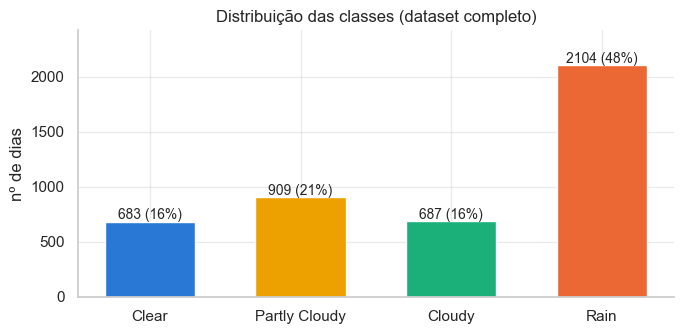

In [14]:
# ---------------------------------------------------------------
# 5.5 Desbalanceamento de classes
# ---------------------------------------------------------------
counts = df["cond_class"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v} ({v / counts.sum():.0%})", ha="center", fontsize=10)
ax.set_title("Distribuição das classes (dataset completo)"); ax.set_ylabel("nº de dias")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); save_fig("eda_class_balance"); plt.show()

**Desbalanceamento:** *Rain* é a classe majoritária (~metade dos dias) e as outras três dividem o resto.
Consequências práticas:
* **Acurácia sozinha engana** – um modelo que sempre diz "Rain" já acerta ~48 %. Por isso a métrica principal da classificação será o **F1‑macro** (média do F1 de cada classe, que dá o mesmo peso às classes minoritárias).
* Usaremos `class_weight="balanced"` nos modelos, para penalizar mais os erros nas classes raras.

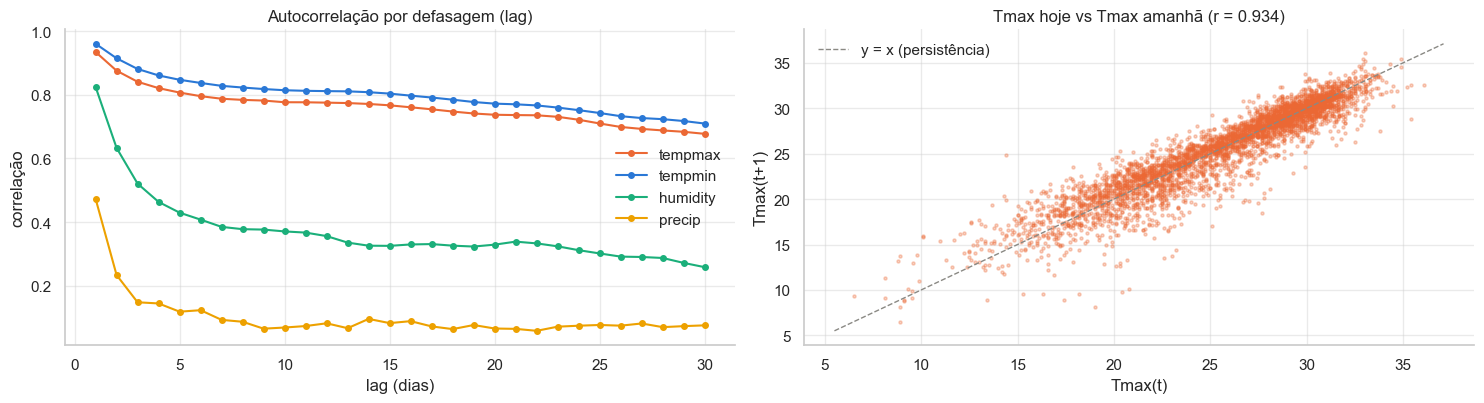

In [15]:
# ---------------------------------------------------------------
# 5.6 Autocorrelação: quão parecido é hoje com ontem, anteontem...?
# ---------------------------------------------------------------
lags = range(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for col, color in [("tempmax", C_ORANGE), ("tempmin", C_BLUE), ("humidity", C_AQUA), ("precip", C_YELLOW)]:
    axes[0].plot(list(lags), [df[col].autocorr(l) for l in lags], marker="o", ms=4, color=color, label=col)
axes[0].set_title("Autocorrelação por defasagem (lag)"); axes[0].set_xlabel("lag (dias)"); axes[0].set_ylabel("correlação")
axes[0].legend(frameon=False)

# Dispersão: Tmax de hoje vs Tmax de amanhã (a lógica do baseline de persistência)
axes[1].scatter(df["tempmax"].iloc[:-1], df["tempmax"].shift(-1).iloc[:-1], s=5, alpha=0.3, color=C_ORANGE)
lims = [df["tempmax"].min() - 1, df["tempmax"].max() + 1]
axes[1].plot(lims, lims, color=C_GRAY, ls="--", lw=1, label="y = x (persistência)")
r = df["tempmax"].autocorr(1)
axes[1].set_title(f"Tmax hoje vs Tmax amanhã (r = {r:.3f})"); axes[1].set_xlabel("Tmax(t)"); axes[1].set_ylabel("Tmax(t+1)")
axes[1].legend(frameon=False)
plt.tight_layout(); save_fig("eda_autocorrelation"); plt.show()

**Por que isso importa:** a temperatura tem autocorrelação **altíssima** no lag 1 (r ≈ 0,93) e decai devagar →
"amanhã ≈ hoje" já é uma previsão forte (o baseline de persistência será **difícil de bater**). Os **lags** (t‑1, t‑2) e as **médias móveis**
capturam essa *memória* da série. A precipitação tem autocorrelação bem menor – a chuva é muito mais "aleatória" de um dia para o outro,
então a classificação é intrinsecamente mais difícil que a regressão.

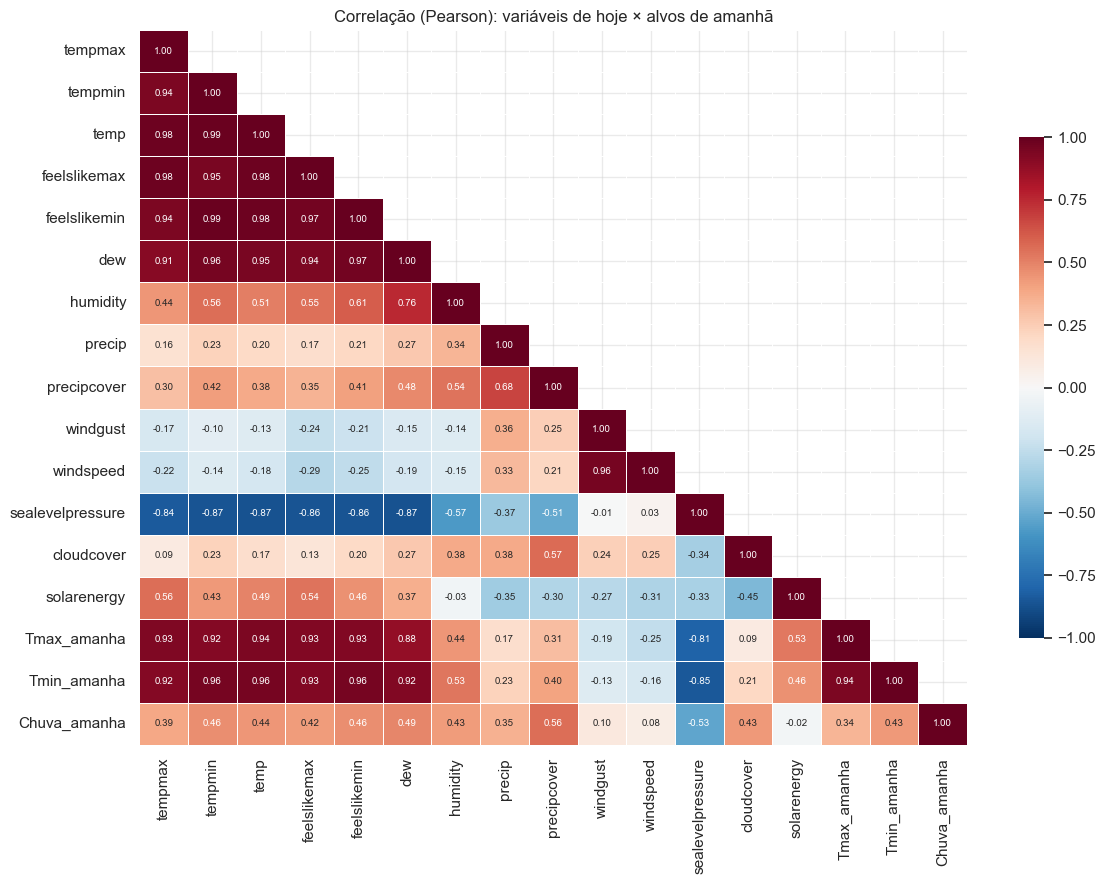

Correlação com os alvos de amanhã (ordenada):


,Tmax_amanha,Tmin_amanha,Chuva_amanha
precipcover,0.31,0.40,0.56
dew,0.88,0.92,0.49
tempmin,0.92,0.96,0.46
feelslikemin,0.93,0.96,0.46
temp,0.94,0.96,0.44
cloudcover,0.09,0.21,0.43
humidity,0.44,0.53,0.43
feelslikemax,0.93,0.93,0.42
tempmax,0.93,0.92,0.39
precip,0.17,0.23,0.35


In [16]:
# ---------------------------------------------------------------
# 5.7 Correlação entre variáveis de HOJE e os alvos de AMANHÃ
# ---------------------------------------------------------------
corr_df = df[NUMERIC_COLS].drop(columns="winddir")
corr_df["Tmax_amanha"] = df["tempmax"].shift(-1)
corr_df["Tmin_amanha"] = df["tempmin"].shift(-1)
corr_df["Chuva_amanha"] = (df["cond_class"].shift(-1) == "Rain").astype(float)
corr = corr_df.dropna().corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlação (Pearson): variáveis de hoje × alvos de amanhã")
plt.tight_layout(); save_fig("eda_correlation"); plt.show()

print("Correlação com os alvos de amanhã (ordenada):")
corr[["Tmax_amanha", "Tmin_amanha", "Chuva_amanha"]].drop(["Tmax_amanha", "Tmin_amanha", "Chuva_amanha"]) \
    .sort_values("Chuva_amanha", ascending=False).round(2)

**Leitura do mapa de correlação:**
* Os alvos de temperatura estão fortemente correlacionados com **todas as temperaturas de hoje** e com o **ponto de orvalho** (ar úmido = noites quentes),
  e **negativamente com a pressão** (pressão alta = massa de ar fria do inverno).
* Há **multicolinearidade** forte entre `temp`, `tempmax`, `feelslike*` e `dew` → para o modelo linear isso pede **regularização (Ridge)**; para as árvores não é problema.
* A **chuva de amanhã** se relaciona com umidade, ponto de orvalho, cobertura de nuvens e `precipcover` de hoje, e negativamente com a pressão e a energia solar.

Média por classe de AMANHÃ (variáveis de hoje):


,humidity,sealevelpressure,dpressao
classe_amanha,,,
Clear,72.96,1017.13,-0.04
Partly Cloudy,77.77,1015.87,-0.02
Cloudy,78.43,1015.08,0.19
Rain,85.53,1009.04,-0.04


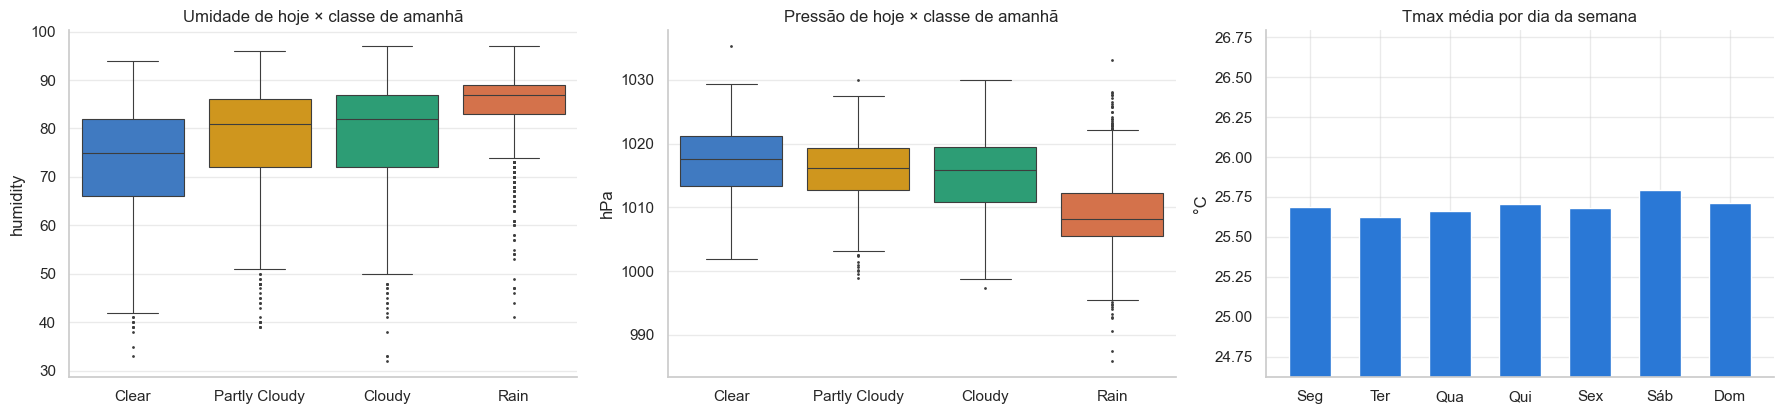

In [17]:
# ---------------------------------------------------------------
# 5.8 Relação features x classe de amanhã + checagem do "dia da semana"
# ---------------------------------------------------------------
tmp = df.copy()
tmp["classe_amanha"] = tmp["cond_class"].shift(-1)
tmp["dpressao"] = tmp["sealevelpressure"].diff()            # variação da pressão de ontem para hoje
tmp = tmp.dropna()
print("Média por classe de AMANHÃ (variáveis de hoje):")
display(tmp.groupby("classe_amanha")[["humidity", "sealevelpressure", "dpressao"]].mean().loc[CLASSES].round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
pal = [CLASS_COLORS[c] for c in CLASSES]
sns.boxplot(data=tmp, x="classe_amanha", y="humidity", order=CLASSES, palette=pal, ax=axes[0], fliersize=1, linewidth=0.8)
axes[0].set_title("Umidade de hoje × classe de amanhã"); axes[0].set_xlabel("")
sns.boxplot(data=tmp, x="classe_amanha", y="sealevelpressure", order=CLASSES, palette=pal, ax=axes[1], fliersize=1, linewidth=0.8)
axes[1].set_title("Pressão de hoje × classe de amanhã"); axes[1].set_xlabel(""); axes[1].set_ylabel("hPa")

# Dia da semana: o tempo NÃO deveria depender do calendário humano
dow = df.groupby(df.index.dayofweek)["tempmax"].mean()
axes[2].bar(["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"], dow.values, color=C_BLUE, width=0.6)
axes[2].set_ylim(dow.min() - 1, dow.max() + 1)
axes[2].set_title("Tmax média por dia da semana"); axes[2].set_ylabel("°C")
plt.tight_layout(); save_fig("eda_relationships"); plt.show()

**Conclusões:**
* Dias seguidos de **Rain** têm umidade mais alta hoje; dias seguidos de **Clear** têm a umidade mais baixa → umidade é preditiva.
* **Pressão alta** (anticiclone, ar seco) antecede dias *Clear*; **pressão baixa** (~1009 hPa, cavados e sistemas tropicais) antecede *Rain*.
  A **variação** diária da pressão, na média do ano todo, quase não difere entre as classes (sinal fraco), mas a mantemos como feature
  por ser fisicamente motivada (frentes frias e sistemas tropicais mudam a pressão) – o modelo decide se ela é útil.
* O **dia da semana não tem efeito** (variação < 0,2 °C entre os dias, puro ruído) – faz sentido físico. A especificação sugere testar features de calendário,
  mas, com base nesta evidência, **não usaremos o dia da semana** como feature (evita ruído e sobreajuste). Da mesma forma, "hora do dia" não se
  aplica, pois os dados são **diários**.

---
## 6. Engenharia de features

**Princípio de ouro (sem vazamento de dados / *data leakage*):** para prever o dia **t+1**, só podemos usar informação disponível
até o **fim do dia t**. Todas as features abaixo usam apenas os dias t, t‑1, t‑2, …; os alvos são deslocados para o futuro com `shift(-1)`.

| Grupo | Features | Por quê |
|---|---|---|
| **Hoje (t)** | as 14 variáveis medidas no dia | o estado atual da atmosfera é o melhor preditor do estado de amanhã |
| **Lags** | valores de t‑1 e t‑2 das variáveis principais | capturam a **dinâmica** (está esquentando? a umidade está subindo?) |
| **Diferenças** | Tmax(t) − Tmax(t‑1), pressão(t) − pressão(t‑1), pressão(t) − pressão(t‑3) | tendência de curto prazo; queda de pressão = chegada de sistemas de chuva |
| **Médias móveis** | médias de 3, 7 e 14 dias (janela termina em t); desvio‑padrão de 7 dias | suavizam o ruído diário e representam o "regime" recente |
| **Físicas / domínio** | amplitude térmica (Tmax−Tmin), depressão do ponto de orvalho (T−Td), anomalia (T − média 30 dias) | Td próximo de T = ar saturado = chuva/nuvens; anomalia indica massa de ar fora do normal |
| **Sazonalidade cíclica** | seno/cosseno do dia do ano e do mês | codifica que 31/dez e 1/jan são vizinhos (o mês "12" não fica longe do "1") |
| **Vento** | seno/cosseno da direção | direção é circular (359° ≈ 1°); vento de N/NE no inverno traz ar frio e seco |
| **Categórica** | classe de hoje em *one‑hot* (4 colunas 0/1) | persistência do tipo de tempo; one‑hot evita impor uma ordem falsa entre classes |

**Escalonamento:** é feito **dentro de um `Pipeline`** com `StandardScaler` apenas para os modelos lineares (Ridge e Regressão Logística),
que são sensíveis à escala. O scaler é ajustado **somente no treino** em cada etapa → sem vazamento. Árvores não precisam de escala.

In [18]:
# 6.1 Engenharia de features (detalhes de cada grupo em wu.build_features)
feat, FEATURES = wu.build_features(df)
print(f"Matriz final: {feat.shape[0]} linhas | {len(FEATURES)} features")
feat.to_csv(PROCESSED_DIR / "macau_features_processed.csv")
feat[FEATURES[:6] + ["tempmax_lag1", "tempmax_roll7", "doy_sin", "target_tmax", "target_tmin", "target_cond"]].head()

Matriz final: 4353 linhas | 76 features


,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,tempmax_lag1,tempmax_roll7,doy_sin,target_tmax,target_tmin,target_cond
date,,,,,,,,,,,,
2014-01-30,20.1,12.2,16.6,21.6,12.2,14.2,20.7,20.028571,0.493468,21.7,14.4,Clear
2014-01-31,21.7,14.4,17.9,23.0,15.5,15.5,20.1,20.442857,0.508356,21.6,15.2,Partly Cloudy
2014-02-01,21.6,15.2,18.4,23.0,16.3,16.6,21.7,20.671429,0.523094,21.8,15.6,Partly Cloudy
2014-02-02,21.8,15.6,18.3,24.0,16.9,16.4,21.6,20.657143,0.537677,23.4,15.4,Clear
2014-02-03,23.4,15.4,19.2,26.0,15.5,15.5,21.8,21.271429,0.552101,21.2,14.9,Partly Cloudy


In [19]:
# ---------------------------------------------------------------
# 6.2 Teste de sanidade anti-vazamento (boa prática de QA)
# ---------------------------------------------------------------
# Se o alvo foi construído corretamente, target_tmax do dia t deve ser IGUAL ao tempmax do dia t+1
check = (feat["target_tmax"].iloc[:-1].values == df.loc[feat.index[1:], "tempmax"].values).mean()
print(f"target_tmax(t) == tempmax(t+1) em {check:.1%} das linhas")
# E nenhuma feature pode ser cópia do alvo (correlação 1.0 perfeita indicaria vazamento)
max_corr = feat[FEATURES].corrwith(feat["target_tmax"]).abs().max()
print(f"Maior |correlação| feature-alvo: {max_corr:.3f}  (< 1 -> nenhuma feature é o próprio alvo)")
assert check > 0.99 and max_corr < 0.999

target_tmax(t) == tempmax(t+1) em 100.0% das linhas
Maior |correlação| feature-alvo: 0.939  (< 1 -> nenhuma feature é o próprio alvo)


---
## 7. Divisão cronológica: treino / validação / teste

Em séries temporais **nunca** usamos divisão aleatória (`train_test_split` com `shuffle`): o modelo veria o futuro durante o treino
(ex.: treinar com 15/jul e testar com 14/jul) e as métricas ficariam artificialmente otimistas.

Usamos blocos cronológicos definidos pela **data do alvo** (o dia previsto):

| Conjunto | Período do alvo | Uso |
|---|---|---|
| **Treino** | 2014 → 2021 (8 anos) | ajustar os modelos; tuning com validação cruzada temporal |
| **Validação** | 2022 → 2023 (2 anos) | comparar modelos e escolher o final |
| **Teste** | 2024 → 2025 (2 anos) | avaliação **única** e final (dados "nunca vistos") |

Dividir pela data do alvo garante que **nenhum rótulo** de um conjunto posterior entre no treino de um anterior.
Dois anos completos em validação e teste cobrem **todas as estações** (inclusive duas temporadas de tufões).

Treino    :  2892 linhas | alvos de 2014-01-31 a 2021-12-31
Validação :   730 linhas | alvos de 2022-01-01 a 2023-12-31
Teste     :   731 linhas | alvos de 2024-01-01 a 2025-12-31


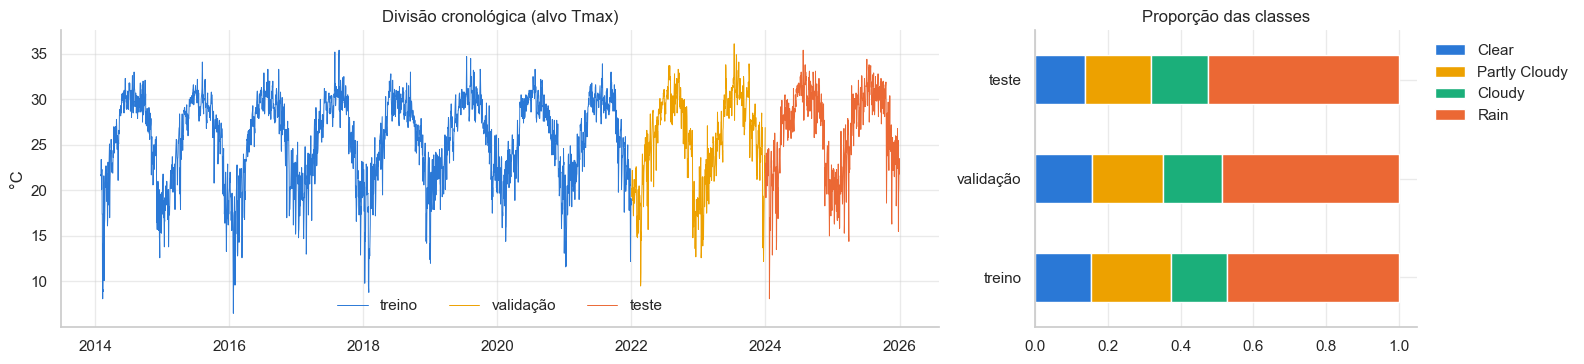

In [20]:
# 7.1 Divisão cronológica pela DATA DO ALVO (sem embaralhar)
td = feat["target_date"]
train, val, test = feat[td <= TRAIN_END], feat[(td > TRAIN_END) & (td <= VAL_END)], feat[td > VAL_END]
for name, part in [("Treino", train), ("Validação", val), ("Teste", test)]:
    print(f"{name:10s}: {len(part):5d} linhas | alvos de {part['target_date'].min().date()} a {part['target_date'].max().date()}")
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]

# Visualização da divisão + proporção de classes em cada parte (as distribuições são parecidas?)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.3, 1]})
for part, color, lab in [(train, C_BLUE, "treino"), (val, C_YELLOW, "validação"), (test, C_ORANGE, "teste")]:
    axes[0].plot(part["target_date"], part["target_tmax"], color=color, lw=0.7, label=lab)
axes[0].set_title("Divisão cronológica (alvo Tmax)"); axes[0].set_ylabel("°C"); axes[0].legend(frameon=False, ncol=3)
dist = pd.DataFrame({n: p["target_cond"].value_counts(normalize=True) for n, p in
                     [("treino", train), ("validação", val), ("teste", test)]}).loc[CLASSES].T
dist.plot.barh(stacked=True, ax=axes[1], color=[CLASS_COLORS[c] for c in CLASSES], edgecolor="white", linewidth=1)
axes[1].set_title("Proporção das classes"); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); save_fig("split"); plt.show()

---
## 8. TAREFA 1 – Regressão: Tmax e Tmin de amanhã

### 8.1 Métricas escolhidas (e por quê)
| Métrica | O que mede | Por que usar |
|---|---|---|
| **MAE** (erro absoluto médio) | erro médio em °C | **métrica principal**: fácil de explicar ("erramos em média 0,9 °C") e robusta a outliers |
| **RMSE** | raiz do erro quadrático médio | penaliza mais os **erros grandes** (ex.: frentes frias não previstas) |
| **R²** | fração da variância explicada | comparação relativa (1 = perfeito, 0 = prever a média) |
| **r de Pearson** | correlação previsão × real | mede se acompanhamos as subidas/descidas |

### 8.2 Modelos
* **Baseline – Persistência:** "Tmax de amanhã = Tmax de hoje" (sugerido pela especificação). Simples, sem treino e – como vimos na autocorrelação – forte.
* **Referência extra – Climatologia:** média histórica (do treino) para aquele dia do ano. Mostra quanto se ganha olhando o estado atual além do calendário.
Comparamos **9 modelos de ML de famílias diferentes**, porque não dá para saber de antemão qual funciona melhor nestes dados:

| Família | Modelos | Ideia |
|---|---|---|
| Lineares | **LinearRegression**, **Ridge** (L2), **Lasso** (L1) | relação linear; a regularização lida com as temperaturas muito correlacionadas (Ridge) ou zera features inúteis (Lasso) |
| Vizinhança | **KNN** | prevê pela média dos dias passados mais parecidos com hoje |
| Kernel | **SVR** (RBF) | regressão de vetores de suporte; captura relações não lineares suaves |
| Árvores em paralelo | **Random Forest**, **Extra Trees** | média de muitas árvores; capturam não‑linearidades e interações, robustas a outliers |
| Boosting | **GradientBoosting**, **HistGradientBoosting** | árvores em sequência, cada uma corrigindo os erros da anterior; costumam ser as melhores em dados tabulares |

Modelos sensíveis à escala (lineares, KNN, SVR) recebem um `StandardScaler` dentro de um `Pipeline`. Os hiperparâmetros iniciais estão
em `wu.make_regressors`. O **melhor na validação**, seja qual for, vai para o grid search (8.6).

Treinamos **um modelo por alvo** (Tmax e Tmin), pois os fatores físicos diferem (Tmax depende do sol/nuvens; Tmin da umidade/nuvens à noite).

In [21]:
# 8.3 Alvos da regressão: coluna-alvo -> (coluna de hoje usada pela persistência, rótulo)
#  Modelos (wu.make_regressors), métricas (wu.regression_metrics) e climatologia ficam em weather_utils.py
REG_TARGETS = {"target_tmax": ("tempmax", "Tmax"), "target_tmin": ("tempmin", "Tmin")}

In [22]:
# 8.4 Baselines + 9 modelos de ML: treino no TREINO, avaliação na VALIDAÇÃO (tabela ordenada pelo MAE)
reg_val_pred, rows = {}, []
for target, (today_col, label) in REG_TARGETS.items():
    preds = {"Persistence": val[today_col].values,                         # amanhã = hoje
             "Climatology": wu.climatology_predict(train, val, target)}    # média histórica do dia do ano
    secs = {}
    for name, model in wu.make_regressors(SEED).items():
        t0 = time.time()
        preds[name] = model.fit(X_train, train[target]).predict(X_val)
        secs[name] = time.time() - t0
    reg_val_pred |= {(target, n): p for n, p in preds.items()}
    rows += [{"alvo": label, "modelo": n, **wu.regression_metrics(val[target], p), "tempo_treino_s": secs.get(n, 0.0)}
             for n, p in preds.items()]
reg_val_table = pd.DataFrame(rows).sort_values(["alvo", "MAE"]).set_index(["alvo", "modelo"]).round(3)
reg_val_table

MAE   RMSE     R2  Pearson_r  tempo_treino_s
alvo modelo                                                          
Tmax GradientBoosting  1.032  1.346  0.926      0.964           6.305
     Ridge             1.033  1.348  0.926      0.963           0.004
     LinearRegression  1.034  1.348  0.926      0.963           0.012
     ExtraTrees        1.048  1.384  0.922      0.962           0.383
     Lasso             1.049  1.375  0.923      0.962           0.040
     HistGradBoost     1.054  1.377  0.922      0.962           2.927
     RandomForest      1.058  1.401  0.920      0.961           1.130
     SVR               1.139  1.504  0.908      0.955           0.357
     KNN               1.217  1.599  0.895      0.950           0.031
     Persistence       1.244  1.716  0.880      0.940           0.000
     Climatology       1.826  2.399  0.765      0.875           0.000
Tmin HistGradBoost     0.993  1.375  0.936      0.968           1.355
     RandomForest      1.000  1.380  0.935      0.967           1.082
     ExtraTrees        1.000  1.386  0.935      0.967           0.424
     GradientBoosting  1.008  1.405  0.933      0.966           6.353
     LinearRegression  1.008  1.398  0.934      0.967           0.006
     Ridge             1.009  1.396  0.934      0.967           0.002
     Lasso             1.011  1.407  0.933      0.966           0.013
     SVR               1.041  1.465  0.927      0.964           0.364
     Persistence       1.101  1.614  0.912      0.956           0.000
     KNN               1.160  1.615  0.912      0.960           0.007
     Climatology       1.756  2.376  0.809      0.902           0.000

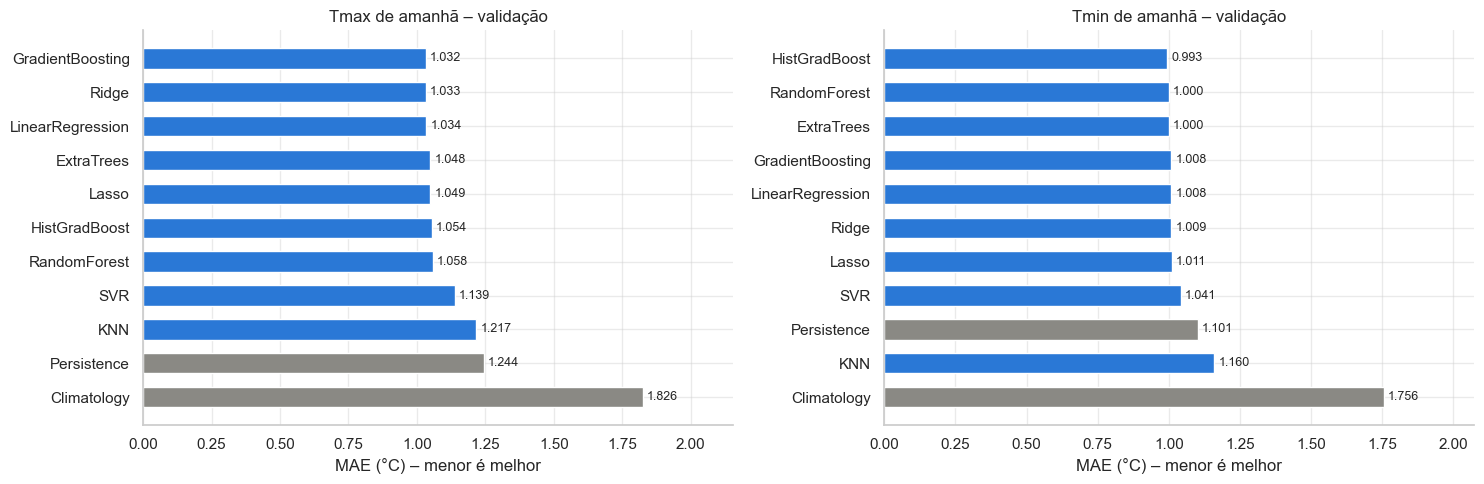

Tmax: melhor modelo na validação = GradientBoosting (MAE 1.032) -> 17.0% melhor que a persistência (MAE 1.244)
Tmin: melhor modelo na validação = HistGradBoost (MAE 0.993) -> 9.8% melhor que a persistência (MAE 1.101)


In [23]:
# 8.5 Comparação visual de todos os modelos (MAE na validação; cinza = baselines)
BASELINES = ["Persistence", "Climatology", "Majority"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, label in zip(axes, ["Tmax", "Tmin"]):
    vals = reg_val_table.loc[label, "MAE"]                       # já ordenado do melhor para o pior
    bars = ax.barh(vals.index, vals.values, height=0.6, color=[C_GRAY if n in BASELINES else C_BLUE for n in vals.index])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, vals.max() * 1.18)
    ax.set_xlabel("MAE (°C) – menor é melhor"); ax.set_title(f"{label} de amanhã – validação")
plt.tight_layout(); save_fig("reg_val_comparison"); plt.show()

for label in ["Tmax", "Tmin"]:                                   # melhoria do melhor modelo sobre a persistência
    t = reg_val_table.loc[label, "MAE"]
    best = t.drop(BASELINES, errors="ignore").idxmin()
    print(f"{label}: melhor modelo na validação = {best} (MAE {t[best]:.3f}) -> "
          f"{1 - t[best] / t['Persistence']:.1%} melhor que a persistência (MAE {t['Persistence']:.3f})")

**Interpretação (validação).**
* Quase todos os modelos de ML **vencem a persistência**; a exceção é o KNN em Tmin. O melhor em Tmax é o **GradientBoosting**
  (1,032 °C contra 1,244 °C, −17 %); em Tmin, o **HistGradBoost** (0,993 °C contra 1,101 °C, −10 %).
* A **climatologia** é bem pior (~1,8 °C): saber só a data não basta; o estado atual da atmosfera é o que mais informa.
* Os modelos do topo ficam separados por **centésimos**: em Tmax, GradientBoosting (1,032), Ridge (1,033) e LinearRegression (1,034)
  praticamente empatam, mas o Ridge treina em 0,002 s contra 6,4 s do GradientBoosting. Ou seja, a relação é majoritariamente linear
  e as features fazem o trabalho pesado.
* **KNN e SVR** ficam para trás: com 76 features, "dias parecidos" medidos por distância são pouco informativos.

> *Os números citados nos textos de interpretação referem‑se à execução de referência (dados Open‑Meteo, semente 42). As tabelas e o resumo da Seção 10 são sempre gerados automaticamente.*

### 8.6 Ajuste de hiperparâmetros (tuning)

**Método:** `GridSearchCV` (testa **todas** as combinações de uma grade) com validação cruzada em **5 folds temporais**
(`TimeSeriesSplit(n_splits=5, gap=1)`), **somente nos dados de treino**. As grades estão em `wu.REG_PARAM_GRIDS`.

* **Por que 5 folds temporais e não um KFold comum?** O KFold comum embaralha os dias: o modelo treinaria com o futuro para prever o
  passado e o erro ficaria otimista (a especificação penaliza divisão aleatória). No `TimeSeriesSplit` cada fold treina no passado e valida
  no período imediatamente seguinte (janela expansível). `gap=1` descarta 1 dia entre treino e validação de cada fold,
  evitando que o alvo do último dia de treino seja a feature do primeiro dia de validação.
* **Por que grid search?** Com grades pequenas (até 27 combinações) dá para testar tudo, e o resultado é fácil de explicar e de reproduzir.
* **Métrica otimizada:** MAE (negativo, pois o scikit‑learn maximiza).
* **Qual modelo ajustar?** O **melhor candidato de ML na validação** (escolhido automaticamente pelo código, como manda a especificação).
  Depois conferimos na validação se o tuning realmente ajudou.

In [24]:
# 8.6 Grid search (5 folds temporais) do melhor modelo de cada alvo (grades em wu.REG_PARAM_GRIDS)
reg_best_name, reg_tuned = {}, {}
for target, (_, label) in REG_TARGETS.items():
    cand = reg_val_table.loc[label].drop(BASELINES, errors="ignore")
    best = reg_best_name[target] = cand["MAE"].idxmin()
    search = wu.tune_model(wu.make_regressors(SEED)[best], wu.REG_PARAM_GRIDS[best], X_train, train[target],
                           "neg_mean_absolute_error")
    reg_tuned[target] = search.best_estimator_
    reg_val_pred[(target, best + "_tuned")] = pred = search.best_estimator_.predict(X_val)
    print(f"{label}: modelo ajustado = {best}\n  Melhores hiperparâmetros: {wu.fmt_params(search.best_params_)}\n"
          f"  MAE CV (treino): {-search.best_score_:.3f} | MAE validação: antes {cand.loc[best, 'MAE']:.3f} "
          f"-> depois {mean_absolute_error(val[target], pred):.3f}")

Tmax: modelo ajustado = GradientBoosting
  Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
  MAE CV (treino): 1.012 | MAE validação: antes 1.032 -> depois 1.035
Tmin: modelo ajustado = HistGradBoost
  Melhores hiperparâmetros: {'learning_rate': 0.02, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}
  MAE CV (treino): 0.925 | MAE validação: antes 0.993 -> depois 0.991


**Interpretação do tuning.** O grid search escolheu a melhor configuração pela validação cruzada temporal no treino, mas na validação
(2022–2023) o ganho foi **nulo ou marginal** (Tmax/GradientBoosting: 1,032 → 1,035, com 200 árvores em vez de 300; Tmin/HistGradBoost: 0,993 → 0,991).
Isso é comum e é uma lição importante:
* os modelos já partiam de hiperparâmetros razoáveis, e o "teto" é dado pela **informação contida nas features**, não pelos hiperparâmetros;
* o melhor ponto nas dobras de 2014–2021 não é necessariamente o melhor para 2022–2023 (mudança de distribuição ao longo do tempo).
Por isso **não confiamos cegamente no tuning** e comparamos com um ensemble na etapa seguinte.

### 8.7 Extensão: Ensemble (combinação de modelos)

A especificação sugere que **combinar modelos** costuma melhorar previsões do tempo. Testamos um *ensemble* de média simples
entre o **modelo ajustado** e o **2º e o 3º melhores modelos da validação** (top‑3). A ideia: modelos de famílias diferentes cometem
**erros diferentes**; ao fazer a média, parte desses erros se cancela (redução de variância).

O **modelo final** de cada alvo é escolhido pela **menor MAE na validação** entre o modelo ajustado e o ensemble.

In [25]:
# 8.7 Ensemble (média do modelo ajustado com o 2º e o 3º melhores da validação) e escolha do modelo final
reg_final_spec, rows = {}, []
for target, (_, label) in REG_TARGETS.items():
    best = reg_best_name[target]
    runners_up = reg_val_table.loc[label, "MAE"].drop(BASELINES + [best], errors="ignore").index[:2]   # 2º e 3º lugares
    members = {n: wu.make_regressors(SEED)[n] for n in runners_up} | {best + "_tuned": reg_tuned[target]}
    reg_val_pred[(target, "Ensemble")] = wu.ensemble(members).fit(X_train, train[target]).predict(X_val)
    rows += [{"alvo": label, "modelo": n, **wu.regression_metrics(val[target], reg_val_pred[(target, n)])}
             for n in [best + "_tuned", "Ensemble"]]
    final = "Ensemble" if rows[-1]["MAE"] < rows[-2]["MAE"] else best + "_tuned"
    # "receita" do modelo final (não treinada), para re-treinar em treino+validação
    reg_final_spec[target] = (final, wu.ensemble(members) if final == "Ensemble" else clone(reg_tuned[target]))
    print(f"{label}: ensemble = {list(members)}")
    print(f"{label}: MAE validação -> {best}_tuned = {rows[-2]['MAE']:.3f} | Ensemble = {rows[-1]['MAE']:.3f}  ==> FINAL: {final}")

reg_val_full = pd.concat([reg_val_table, pd.DataFrame(rows).set_index(["alvo", "modelo"]).round(3)]).sort_index(level=0, sort_remaining=False)
reg_val_full.to_csv(RESULTS_DIR / "regression_validation_results.csv")
reg_val_full

Tmax: ensemble = ['Ridge', 'LinearRegression', 'GradientBoosting_tuned']
Tmax: MAE validação -> GradientBoosting_tuned = 1.035 | Ensemble = 1.011  ==> FINAL: Ensemble
Tmin: ensemble = ['RandomForest', 'ExtraTrees', 'HistGradBoost_tuned']
Tmin: MAE validação -> HistGradBoost_tuned = 0.991 | Ensemble = 0.988  ==> FINAL: Ensemble


MAE   RMSE     R2  Pearson_r  tempo_treino_s
alvo modelo                                                                
Tmax GradientBoosting        1.032  1.346  0.926      0.964           6.305
     Ridge                   1.033  1.348  0.926      0.963           0.004
     LinearRegression        1.034  1.348  0.926      0.963           0.012
     ExtraTrees              1.048  1.384  0.922      0.962           0.383
     Lasso                   1.049  1.375  0.923      0.962           0.040
     HistGradBoost           1.054  1.377  0.922      0.962           2.927
     RandomForest            1.058  1.401  0.920      0.961           1.130
     SVR                     1.139  1.504  0.908      0.955           0.357
     KNN                     1.217  1.599  0.895      0.950           0.031
     Persistence             1.244  1.716  0.880      0.940           0.000
     Climatology             1.826  2.399  0.765      0.875           0.000
     GradientBoosting_tuned  1.035  1.357  0.925      0.963             NaN
     Ensemble                1.011  1.321  0.929      0.965             NaN
Tmin HistGradBoost           0.993  1.375  0.936      0.968           1.355
     RandomForest            1.000  1.380  0.935      0.967           1.082
     ExtraTrees              1.000  1.386  0.935      0.967           0.424
     GradientBoosting        1.008  1.405  0.933      0.966           6.353
     LinearRegression        1.008  1.398  0.934      0.967           0.006
     Ridge                   1.009  1.396  0.934      0.967           0.002
     Lasso                   1.011  1.407  0.933      0.966           0.013
     SVR                     1.041  1.465  0.927      0.964           0.364
     Persistence             1.101  1.614  0.912      0.956           0.000
     KNN                     1.160  1.615  0.912      0.960           0.007
     Climatology             1.756  2.376  0.809      0.902           0.000
     HistGradBoost_tuned     0.991  1.377  0.936      0.968             NaN
     Ensemble                0.988  1.368  0.937      0.968             NaN

**Interpretação.** O **ensemble** foi o melhor nos dois alvos (Tmax 1,011 °C; Tmin 0,988 °C na validação). Em Tmax ele junta o
GradientBoosting ajustado com **Ridge e LinearRegression**: boosting de árvores e modelos lineares erram em situações diferentes, e a
média cancela parte desses erros (1,035 → 1,011). Em Tmin os três melhores são modelos de árvores (HistGradBoost, Random Forest, Extra Trees);
como modelos parecidos erram de forma parecida, o ganho é menor (0,991 → 0,988).

### 8.8 Avaliação final no conjunto de TESTE (uma única vez)

Procedimento correto:
1. Re‑treinamos o modelo final em **treino + validação** (mais dados, incluindo os anos mais recentes) com a configuração já escolhida;
2. Avaliamos **uma única vez** no teste (2024–2025), comparando com os baselines. Nada é ajustado depois disso.

Também estimamos se a melhoria sobre a persistência é **estatisticamente e praticamente significativa** com um
**bootstrap em blocos** (*moving block bootstrap*): reamostramos blocos de 7 dias consecutivos (preservando a autocorrelação dos erros, que um bootstrap
comum ignoraria) e calculamos o intervalo de confiança de 95 % da diferença de MAE.

In [26]:
# 8.8 Re-treino em treino+validação e avaliação ÚNICA no teste (+ bootstrap em blocos vs persistência)
trainval = pd.concat([train, val])
rows, reg_test_pred = [], {}
for target, (today_col, label) in REG_TARGETS.items():
    final_name, recipe = reg_final_spec[target]
    final_model = recipe.fit(trainval[FEATURES], trainval[target])
    preds = reg_test_pred[target] = {"Persistence": test[today_col].values,
                                     "Climatology": wu.climatology_predict(trainval, test, target),
                                     f"FINAL ({final_name})": final_model.predict(X_test)}
    rows += [{"alvo": label, "modelo": n, **wu.regression_metrics(test[target], p)} for n, p in preds.items()]
    lo, hi = wu.block_bootstrap_diff(test[target], preds[f"FINAL ({final_name})"], preds["Persistence"], mean_absolute_error)
    print(f"{label}: redução de MAE vs persistência = IC95% [{lo:.3f}, {hi:.3f}] °C -> {'significativa' if lo > 0 else 'NÃO significativa'}")
    joblib.dump(final_model, MODELS_DIR / f"final_regressor_{label}.joblib")

reg_test_table = pd.DataFrame(rows).set_index(["alvo", "modelo"]).round(3)
reg_test_table.to_csv(RESULTS_DIR / "regression_test_results.csv")
reg_test_table

Tmax: redução de MAE vs persistência = IC95% [0.211, 0.356] °C -> significativa
Tmin: redução de MAE vs persistência = IC95% [0.072, 0.173] °C -> significativa


MAE   RMSE     R2  Pearson_r
alvo modelo                                          
Tmax Persistence       1.510  2.060  0.808      0.904
     Climatology       2.139  2.676  0.677      0.853
     FINAL (Ensemble)  1.220  1.605  0.884      0.942
Tmin Persistence       1.107  1.582  0.912      0.956
     Climatology       1.790  2.380  0.800      0.895
     FINAL (Ensemble)  0.987  1.382  0.933      0.967

Tmax: MAE inverno (nov-mar) persist. 1.91 -> modelo 1.43 | verão (mai-set) persist. 1.10 -> modelo 0.97
Tmin: MAE inverno (nov-mar) persist. 1.50 -> modelo 1.31 | verão (mai-set) persist. 0.72 -> modelo 0.68


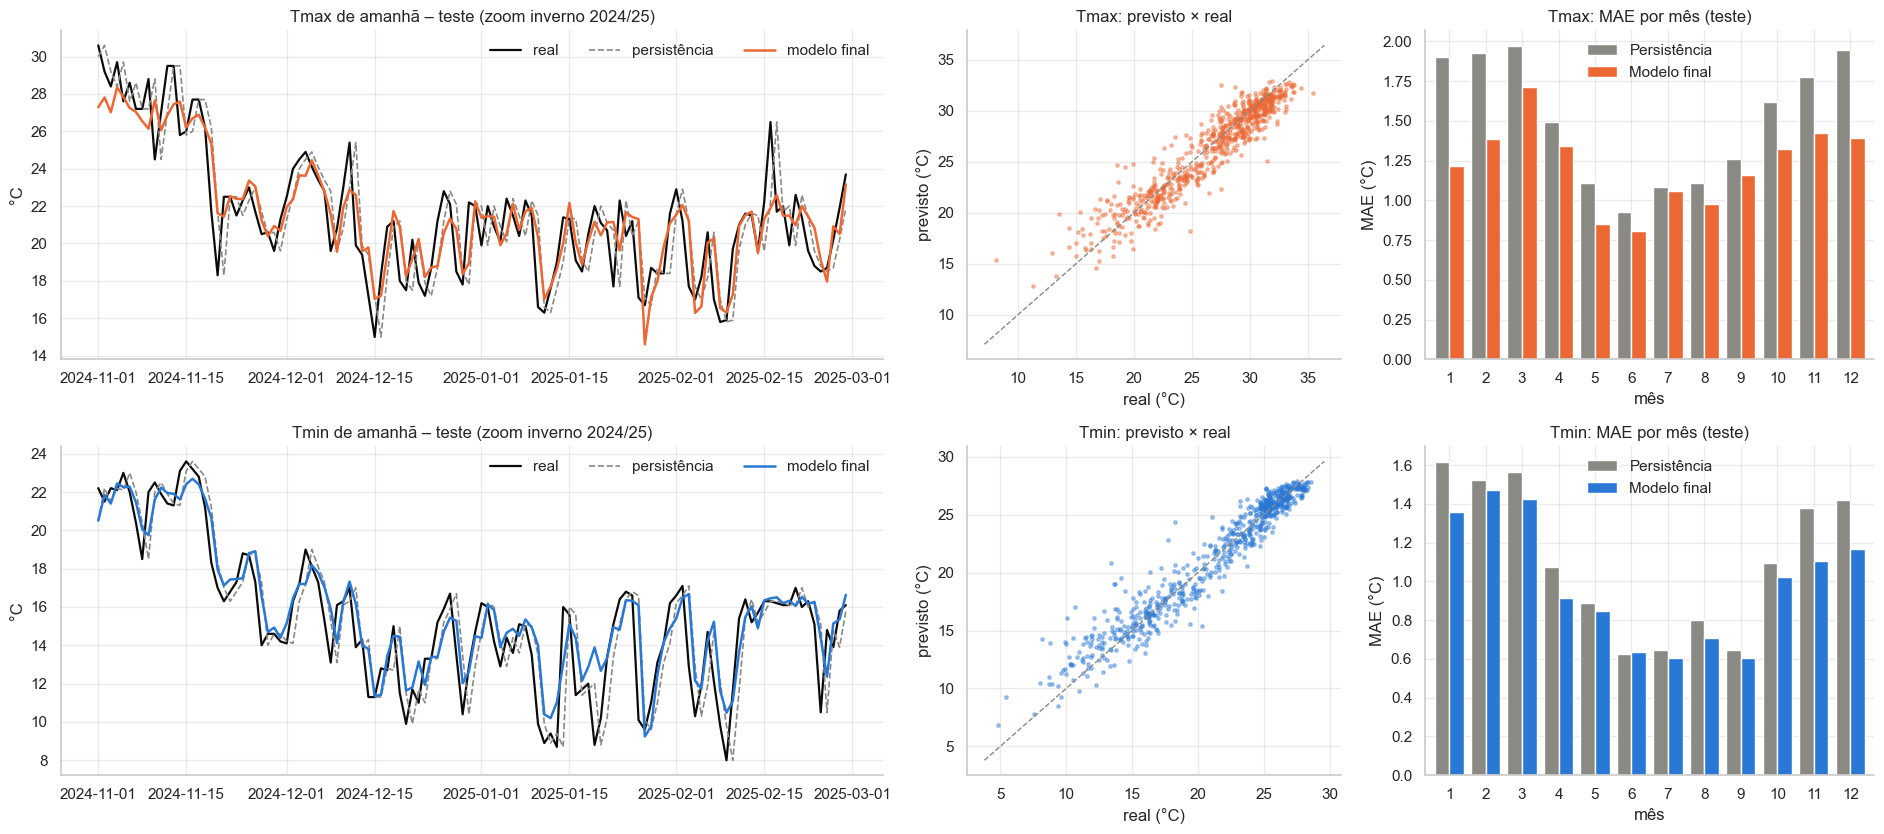

In [27]:
# ---------------------------------------------------------------
# 8.9 Gráficos do teste: série prevista x real, dispersão e erro por mês
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(19, 8.5), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})
for row, (target, (today_col, label)) in enumerate(REG_TARGETS.items()):
    preds = reg_test_pred[target]
    fname = [k for k in preds if k.startswith("FINAL")][0]
    dates, y_te = test["target_date"], test[target]

    # (a) Zoom em 120 dias do teste (inverno 2024/25, quando as mudanças são mais bruscas)
    win = (dates >= "2024-11-01") & (dates < "2025-03-01")
    ax = axes[row, 0]
    ax.plot(dates[win], y_te[win], color="#0b0b0b", lw=1.6, label="real")
    ax.plot(dates[win], preds["Persistence"][win.values], color=C_GRAY, lw=1.2, ls="--", label="persistência")
    ax.plot(dates[win], preds[fname][win.values], color=C_ORANGE if label == "Tmax" else C_BLUE, lw=1.8, label="modelo final")
    ax.set_title(f"{label} de amanhã – teste (zoom inverno 2024/25)"); ax.set_ylabel("°C"); ax.legend(frameon=False, ncol=3)

    # (b) Dispersão previsto x real
    ax = axes[row, 1]
    ax.scatter(y_te, preds[fname], s=6, alpha=0.4, color=C_ORANGE if label == "Tmax" else C_BLUE)
    lims = [y_te.min() - 1, y_te.max() + 1]
    ax.plot(lims, lims, color=C_GRAY, ls="--", lw=1)
    ax.set_title(f"{label}: previsto × real"); ax.set_xlabel("real (°C)"); ax.set_ylabel("previsto (°C)")

    # (c) MAE por mês: onde o modelo erra mais?
    ax = axes[row, 2]
    err = pd.DataFrame({"mes": dates.dt.month.values,
                        "Persistência": np.abs(y_te.values - preds["Persistence"]),
                        "Modelo final": np.abs(y_te.values - preds[fname])}).groupby("mes").mean()
    err.plot.bar(ax=ax, color=[C_GRAY, C_ORANGE if label == "Tmax" else C_BLUE], width=0.8, edgecolor="white")
    ax.set_title(f"{label}: MAE por mês (teste)"); ax.set_ylabel("MAE (°C)"); ax.set_xlabel("mês")
    ax.tick_params(axis="x", rotation=0); ax.legend(frameon=False)
    winter, summer = err.loc[[11, 12, 1, 2, 3]].mean(), err.loc[[5, 6, 7, 8, 9]].mean()
    print(f"{label}: MAE inverno (nov-mar) persist. {winter['Persistência']:.2f} -> modelo {winter['Modelo final']:.2f} | "
          f"verão (mai-set) persist. {summer['Persistência']:.2f} -> modelo {summer['Modelo final']:.2f}")
plt.tight_layout(); save_fig("reg_test_results"); plt.show()

**Interpretação (teste 2024–2025).**
* O modelo final reduziu o MAE em **~19 % (Tmax: 1,51 → 1,22 °C)** e **~11 % (Tmin: 1,11 → 0,99 °C)** em relação à persistência, e o
  **bootstrap em blocos** mostra que a redução é **estatisticamente significativa** (IC95 % de [0,21; 0,36] °C em Tmax e [0,07; 0,17] °C em Tmin).
* **Onde está o ganho?** No **inverno** (nov–mar), quando frentes frias provocam quedas bruscas: Tmax 1,91 → 1,43 °C. No verão, quando o tempo
  é estável, a persistência já é boa e o ganho é menor (1,10 → 0,97 °C). Ou seja, o modelo ajuda **justamente nos dias em que a previsão mais importa**.
* No gráfico de zoom, a persistência é a curva real **atrasada em 1 dia**; o modelo final antecipa parte das mudanças, mas ainda **suaviza os extremos**
  (subestima picos e vales) – limitação típica de modelos que minimizam erro médio.

### 8.10 Importância das features (interpretação do modelo)

Usamos **Permutation Importance**: embaralhamos uma feature por vez na **validação** e medimos quanto o MAE piora.
Se a feature for importante, embaralhá‑la destrói informação e o erro sobe. Vantagens: é **agnóstica ao modelo** (funciona para Ridge, RF,
boosting e ensemble) e é medida em dados **fora do treino** (diferente da importância por impureza das árvores, que é enviesada para
features contínuas). Usamos o modelo ajustado treinado só no treino, para não tocar no teste.

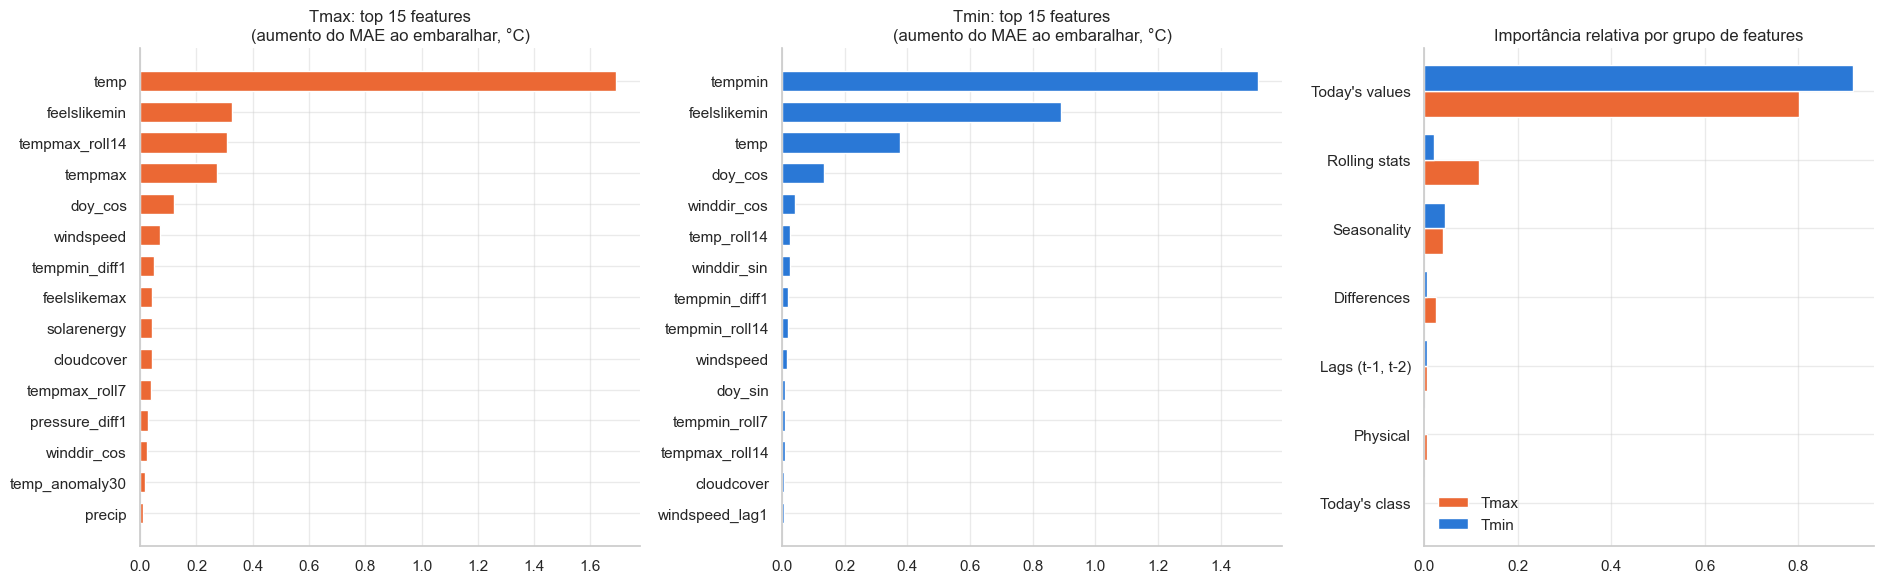

In [28]:
# 8.10 Permutation importance na validação (modelo ajustado, treinado só no treino)
fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
group_imp = {}
for ax, (target, (_, label)) in zip(axes[:2], REG_TARGETS.items()):
    pi = permutation_importance(reg_tuned[target], X_val, val[target], scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
    group_imp[label] = imp.clip(lower=0).groupby(imp.index.map(wu.feature_group)).sum()
    top = imp.head(15)[::-1]
    ax.barh(top.index, top.values, color=C_ORANGE if label == "Tmax" else C_BLUE, height=0.65)
    ax.set_title(f"{label}: top 15 features\n(aumento do MAE ao embaralhar, °C)")
gi = pd.DataFrame(group_imp)
(gi / gi.sum()).sort_values("Tmax").plot.barh(ax=axes[2], color=[C_ORANGE, C_BLUE], width=0.75)
axes[2].set_title("Importância relativa por grupo de features"); axes[2].legend(frameon=False)
plt.tight_layout(); save_fig("reg_feature_importance"); plt.show()

**Interpretação da importância.**
* Em ambos os alvos dominam as **variáveis de hoje** (Tmax: `temp`, `feelslikemin`, `tempmax`; Tmin: `tempmin`, `feelslikemin`, `temp`),
  seguidas de **médias móveis** (`tempmax_roll14`), **sazonalidade** (`doy_cos`) e **diferenças**.
* Em Tmax (GradientBoosting ajustado) aparecem `windspeed` e `tempmin_diff1`: vento forte e queda da mínima indicam chegada de **ar frio** (monção de NE).
* **Cuidado ao interpretar:** features muito correlacionadas (`temp`, `tempmin`, `feelslikemin`) "dividem" a importância entre si – embaralhar uma delas
  pouco importa se as outras carregam a mesma informação. Por isso o resumo **por grupo** (gráfico à direita) é mais confiável que o ranking individual.

---
## 9. TAREFA 2 – Classificação: condição do tempo de amanhã

### 9.1 Métricas escolhidas
| Métrica | Por que usar |
|---|---|
| **F1‑macro** (principal) | média do F1 das 4 classes com **peso igual** → não é "enganada" pelo desbalanceamento; exige acertar também Clear/Cloudy |
| **Acurácia** | intuitiva para o público geral, mas inflada pela classe majoritária |
| **Acurácia balanceada** | média do *recall* por classe |
| **Precisão / Recall / F1 por classe** + **matriz de confusão** | mostram **quais classes** são confundidas entre si |

### 9.2 Modelos
* **Baseline – Classe majoritária:** sempre prever a classe mais frequente do treino (sugerido pela especificação).
* **Referência extra – Persistência:** "amanhã terá a mesma condição de hoje" – um baseline bem mais exigente.
* **8 classificadores de ML:** Regressão Logística, KNN, SVC (RBF), Naive Bayes, Random Forest, Extra Trees, GradientBoosting e
  HistGradientBoosting (mesmas famílias da regressão, mais o **Naive Bayes**, um modelo probabilístico simples que assume features independentes).
  O **melhor na validação** vai para o grid search (9.5).

`class_weight` aumenta o peso dos erros nas classes raras (inverso da frequência), combatendo o desbalanceamento **sem** criar dados sintéticos.
Os modelos que aceitam esse parâmetro (Logística, SVC, Random Forest, Extra Trees e HistGradientBoosting) o usam; KNN, Naive Bayes e GradientBoosting não têm essa opção.

In [29]:
# 9.3 Alvos da classificação (modelos e métricas em wu.make_classifiers / wu.classification_metrics)
y_train_c, y_val_c, y_test_c = train["target_cond"], val["target_cond"], test["target_cond"]

In [30]:
# 9.4 Baselines + 8 classificadores: treino no TREINO, avaliação na VALIDAÇÃO (tabela ordenada pelo F1-macro)
majority = y_train_c.mode()[0]
clf_val_pred = {"Majority": np.full(len(val), majority), "Persistence": wu.persistence_class(val)}
clf_fitted, secs = {}, {}
for name, model in wu.make_classifiers(SEED).items():
    t0 = time.time()
    clf_val_pred[name] = model.fit(X_train, y_train_c).predict(X_val)
    secs[name] = time.time() - t0
print(f"Classe majoritária no treino: {majority}")
clf_val_table = pd.DataFrame({n: {**wu.classification_metrics(y_val_c, p), "tempo_treino_s": secs.get(n, 0.0)}
                              for n, p in clf_val_pred.items()}).T.sort_values("F1_macro", ascending=False).astype(float).round(3)
clf_val_table

Classe majoritária no treino: Rain


,F1_macro,Accuracy,Balanced_acc,F1_weighted,tempo_treino_s
ExtraTrees,0.532,0.604,0.534,0.609,0.254
RandomForest,0.530,0.619,0.527,0.613,0.584
LogisticReg,0.524,0.584,0.547,0.593,0.059
Persistence,0.523,0.599,0.522,0.599,0.000
SVC,0.522,0.573,0.533,0.590,0.971
KNN,0.510,0.619,0.511,0.602,0.010
GradientBoosting,0.510,0.618,0.503,0.598,17.134
HistGradBoost,0.498,0.607,0.497,0.593,4.324
NaiveBayes,0.448,0.553,0.465,0.540,0.004
Majority,0.164,0.486,0.250,0.318,0.000


**Interpretação (validação).**
* A **classe majoritária** acerta ~49 % (acurácia), mas seu F1‑macro é só **0,16** – exemplo clássico de por que acurácia engana com classes desbalanceadas.
* A **persistência** é forte (F1‑macro 0,52, acurácia 0,60): o tipo de tempo tende a se repetir por vários dias.
* Dos 8 modelos, só três superam a persistência em F1‑macro, e por pouco: **Extra Trees 0,532**, Random Forest 0,530 e Regressão Logística 0,524
  (esta com a melhor acurácia balanceada, 0,547). O SVC empata; KNN, GradientBoosting e HistGradBoost ficam abaixo.
* O **Naive Bayes** é o pior (0,448): ele supõe features independentes, o que é falso aqui (temperaturas, umidade e ponto de orvalho são muito correlacionados).
* A classificação de 4 classes com dados de um único ponto tem um **teto baixo**, como antecipado pela baixa autocorrelação da chuva na EDA.

### 9.5 Tuning do melhor classificador

Mesmo protocolo da regressão: `GridSearchCV` com 5 folds temporais (`TimeSeriesSplit(5, gap=1)`) no treino, agora otimizando **F1‑macro**. Grades em `wu.CLF_PARAM_GRIDS`.

In [31]:
# 9.5 Grid search (5 folds temporais) do melhor classificador (grades em wu.CLF_PARAM_GRIDS), otimizando F1-macro
clf_best = clf_val_table.drop(BASELINES, errors="ignore")["F1_macro"].idxmax()
clf_search = wu.tune_model(wu.make_classifiers(SEED)[clf_best], wu.CLF_PARAM_GRIDS[clf_best], X_train, y_train_c, "f1_macro")
clf_tuned = clf_search.best_estimator_
clf_val_pred[clf_best + "_tuned"] = clf_tuned.predict(X_val)
f1_after = wu.f1_macro(y_val_c, clf_val_pred[clf_best + "_tuned"])
print(f"Modelo ajustado: {clf_best}\nMelhores hiperparâmetros: {wu.fmt_params(clf_search.best_params_)}")
print(f"F1-macro CV (treino): {clf_search.best_score_:.3f} | validação: antes {clf_val_table.loc[clf_best, 'F1_macro']:.3f} -> depois {f1_after:.3f}")

Modelo ajustado: ExtraTrees
Melhores hiperparâmetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 400}
F1-macro CV (treino): 0.512 | validação: antes 0.532 -> depois 0.514


### 9.6 Extensão: Ensemble por *soft voting*

Fazemos a **média das probabilidades** previstas pelos três melhores classificadores da validação (o ajustado + o 2º e o 3º) e escolhemos a classe
com maior probabilidade média. *Soft voting* aproveita a "confiança" de cada modelo, não só o voto final.
O modelo final é o de maior **F1‑macro na validação** (ajustado × ensemble).

Ensemble: ['RandomForest', 'LogisticReg', 'ExtraTrees_tuned']
F1-macro validação -> ExtraTrees_tuned = 0.514 | Ensemble = 0.539  ==> FINAL: Ensemble


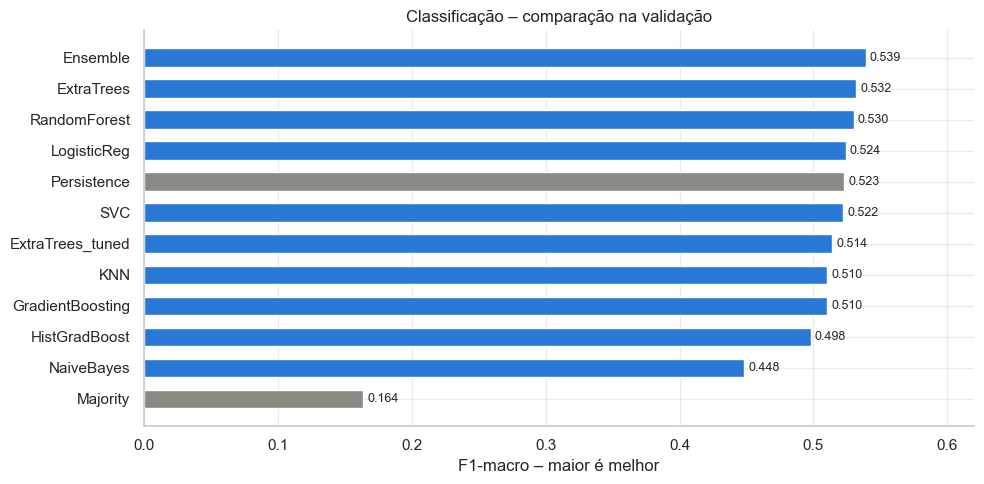

,F1_macro,Accuracy,Balanced_acc,F1_weighted
Ensemble,0.539,0.605,0.546,0.612
ExtraTrees,0.532,0.604,0.534,0.609
RandomForest,0.530,0.619,0.527,0.613
LogisticReg,0.524,0.584,0.547,0.593
Persistence,0.523,0.599,0.522,0.599
SVC,0.522,0.573,0.533,0.590
ExtraTrees_tuned,0.514,0.568,0.523,0.583
KNN,0.510,0.619,0.511,0.602
GradientBoosting,0.510,0.618,0.503,0.598
HistGradBoost,0.498,0.607,0.497,0.593


In [32]:
# 9.6 Soft voting (ajustado + 2º e 3º melhores da validação) e escolha do classificador final
runners_up = clf_val_table["F1_macro"].drop(BASELINES + [clf_best], errors="ignore").index[:2]   # 2º e 3º lugares
clf_members = {n: wu.make_classifiers(SEED)[n] for n in runners_up} | {clf_best + "_tuned": clf_tuned}
print("Ensemble:", list(clf_members))
clf_val_pred["Ensemble"] = wu.ensemble(clf_members).fit(X_train, y_train_c).predict(X_val)
f1_ens = wu.f1_macro(y_val_c, clf_val_pred["Ensemble"])
clf_final_name = "Ensemble" if f1_ens > f1_after else clf_best + "_tuned"
clf_final_recipe = wu.ensemble(clf_members) if clf_final_name == "Ensemble" else clone(clf_tuned)
print(f"F1-macro validação -> {clf_best}_tuned = {f1_after:.3f} | Ensemble = {f1_ens:.3f}  ==> FINAL: {clf_final_name}")

clf_val_full = pd.DataFrame({n: wu.classification_metrics(y_val_c, p) for n, p in clf_val_pred.items()}).T.sort_values("F1_macro", ascending=False).round(3)
clf_val_full.to_csv(RESULTS_DIR / "classification_validation_results.csv")

fig, ax = plt.subplots(figsize=(10, 5))
vals = clf_val_full["F1_macro"]
bars = ax.barh(vals.index, vals.values, height=0.6,
               color=[C_GRAY if n in BASELINES else C_BLUE for n in vals.index])
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, vals.max() * 1.15)
ax.set_xlabel("F1-macro – maior é melhor"); ax.set_title("Classificação – comparação na validação")
plt.tight_layout(); save_fig("clf_val_comparison"); plt.show()
clf_val_full

**Interpretação.** O grid search do Extra Trees **piorou** o desempenho na validação (0,532 → 0,514): a configuração que venceu nas dobras de
2014–2021 (árvores mais rasas, `max_depth=10`) não se repetiu em 2022–2023. Já o **ensemble por soft voting** (Extra Trees ajustado +
Random Forest + Regressão Logística) foi o melhor (0,539) e, pelo critério pré‑definido (maior F1‑macro na validação), virou o **modelo final**.
Ele mistura árvores com um modelo linear, que erram de formas diferentes. Mesmo assim, todos os candidatos ficaram entre 0,51 e 0,54,
confirmando que o limite está **nos dados**, não no algoritmo.

### 9.7 Avaliação final no TESTE (uma única vez)
Re‑treino do modelo final em treino + validação e avaliação única em 2024–2025, com relatório por classe, matriz de confusão
e bootstrap em blocos para a diferença de F1‑macro em relação à persistência.

In [33]:
# 9.7 Re-treino em treino+validação e avaliação ÚNICA no teste
clf_final = clf_final_recipe.fit(trainval[FEATURES], trainval["target_cond"])
joblib.dump(clf_final, MODELS_DIR / "final_classifier.joblib")
final_key = f"FINAL ({clf_final_name})"
clf_test_pred = {"Majority": np.full(len(test), trainval["target_cond"].mode()[0]),
                 "Persistence": wu.persistence_class(test), final_key: clf_final.predict(X_test)}
clf_test_table = pd.DataFrame({n: wu.classification_metrics(y_test_c, p) for n, p in clf_test_pred.items()}).T.round(3)
clf_test_table.to_csv(RESULTS_DIR / "classification_test_results.csv")

lo, hi = wu.block_bootstrap_diff(y_test_c.values, clf_test_pred["Persistence"], clf_test_pred[final_key], wu.f1_macro)
print(f"Ganho de F1-macro vs persistência: IC95% [{lo:.3f}, {hi:.3f}] -> {'significativo' if lo > 0 else 'NÃO significativo'}\n")
print("Relatório por classe (modelo final, teste):")
print(classification_report(y_test_c, clf_test_pred[final_key], labels=CLASSES, digits=3))
clf_test_table

Ganho de F1-macro vs persistência: IC95% [-0.022, 0.045] -> NÃO significativo

Relatório por classe (modelo final, teste):
               precision    recall  f1-score   support

        Clear      0.460     0.634     0.533       101
Partly Cloudy      0.311     0.282     0.296       131
       Cloudy      0.372     0.362     0.367       116
         Rain      0.833     0.783     0.808       383

     accuracy                          0.606       731
    macro avg      0.494     0.515     0.501       731
 weighted avg      0.615     0.606     0.608       731



,F1_macro,Accuracy,Balanced_acc,F1_weighted
Majority,0.172,0.524,0.250,0.360
Persistence,0.489,0.596,0.490,0.596
FINAL (Ensemble),0.501,0.606,0.515,0.608


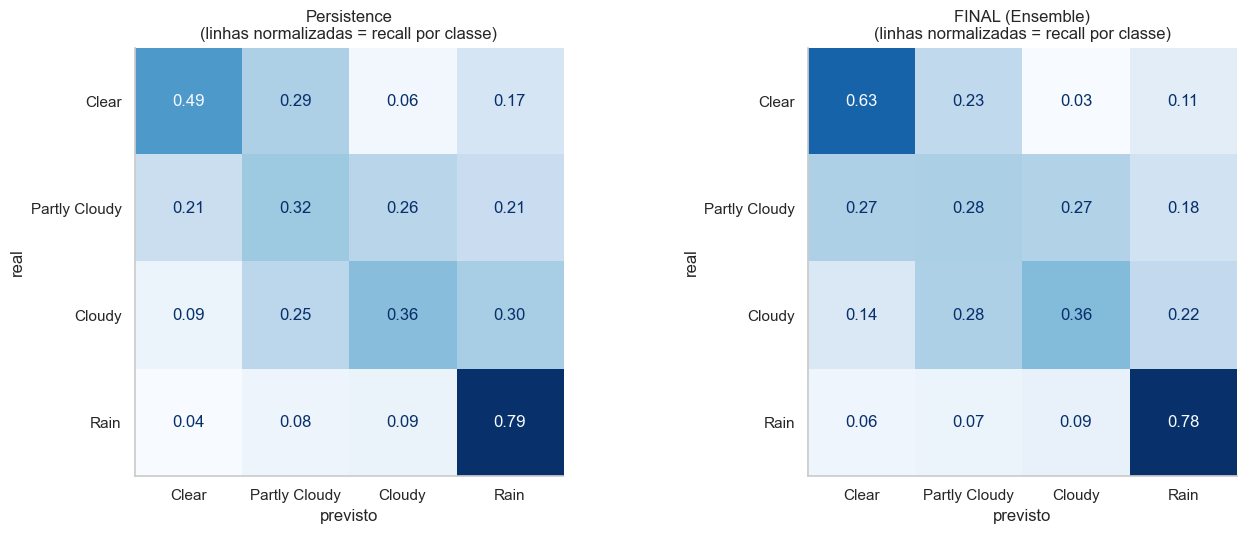

In [34]:
# ---------------------------------------------------------------
# 9.8 Matrizes de confusão (teste): persistência x modelo final
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, ["Persistence", final_key]):
    cm = confusion_matrix(y_test_c, clf_test_pred[name], labels=CLASSES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{name}\n(linhas normalizadas = recall por classe)")
    ax.grid(False); ax.set_xlabel("previsto"); ax.set_ylabel("real")
plt.tight_layout(); save_fig("clf_confusion_matrices"); plt.show()

**Interpretação (teste 2024–2025).**
* Em 4 classes, o modelo final fica ligeiramente acima da persistência (F1‑macro **0,501 × 0,489**; acurácia 0,606 × 0,596), mas o bootstrap
  mostra que a diferença **não é significativa** (IC95 % de [−0,022; 0,045]). Relatamos isso com honestidade: para esta tarefa, o ML
  **não trouxe um ganho comprovado** sobre "amanhã será igual a hoje".
* **Rain** é bem prevista (F1 ≈ 0,81). Os erros se concentram em **Partly Cloudy × Cloudy × Clear** (F1 de 0,30 a 0,53): a matriz de confusão mostra que
  essas classes se misturam entre si – a fronteira é um limiar arbitrário de cobertura de nuvens, e dias perto do limiar são quase "cara ou coroa".
* O modelo melhora bastante o *recall* de **Clear** (0,49 → 0,63), útil para quem planeja atividades ao ar livre.

### 9.9 Visão prática: "vai chover amanhã?" (chuva × sem chuva)

Para o público geral, a pergunta mais útil é binária. Agrupamos as previsões em **Rain × Não‑Rain** e, como o modelo final
fornece **probabilidades**, também medimos o **ROC‑AUC** (capacidade de ordenar dias mais/menos chuvosos; 0,5 = aleatório)
e o **Brier score** (erro quadrático da probabilidade; menor é melhor). Esta é uma vantagem real do ML: a persistência só diz
"sim/não", enquanto o modelo pode dizer **"70 % de chance de chuva"**.

In [35]:
# 9.9 Avaliação binária de chuva (teste) + qualidade da probabilidade de chuva
rain_true = (y_test_c == "Rain").values
p_rain_model = clf_final.predict_proba(X_test)[:, list(clf_final.classes_).index("Rain")]
p_rain_clim = np.full(len(test), (trainval["target_cond"] == "Rain").mean())   # probabilidade climatológica constante
print(f"ROC-AUC P(Rain) do modelo final : {roc_auc_score(rain_true, p_rain_model):.3f}")
print(f"Brier score modelo final        : {brier_score_loss(rain_true, p_rain_model):.3f}")
print(f"Brier score climatologia (const): {brier_score_loss(rain_true, p_rain_clim):.3f}")
bin_table = pd.DataFrame({n: wu.rain_metrics(y_test_c, p) for n, p in clf_test_pred.items()}).T.round(3)
bin_table.to_csv(RESULTS_DIR / "rain_binary_test_results.csv")
bin_table

ROC-AUC P(Rain) do modelo final : 0.884
Brier score modelo final        : 0.160
Brier score climatologia (const): 0.252


,Accuracy,Precision_rain,Recall_rain,F1_rain
Majority,0.524,0.524,1.000,0.688
Persistence,0.781,0.791,0.791,0.791
FINAL (Ensemble),0.804,0.833,0.783,0.808


**Interpretação.** Na pergunta binária o modelo é ligeiramente melhor que a persistência (acurácia 0,80 × 0,78; precisão da chuva 0,83 × 0,79;
F1 da chuva 0,81 × 0,79), mas o ganho mais valioso é a **probabilidade**: ROC‑AUC de **0,88** e Brier score **0,160** contra 0,252 da
probabilidade climatológica (redução de ~37 %). Isso permite comunicar previsões como "80 % de chance de chuva", algo que a persistência não oferece.

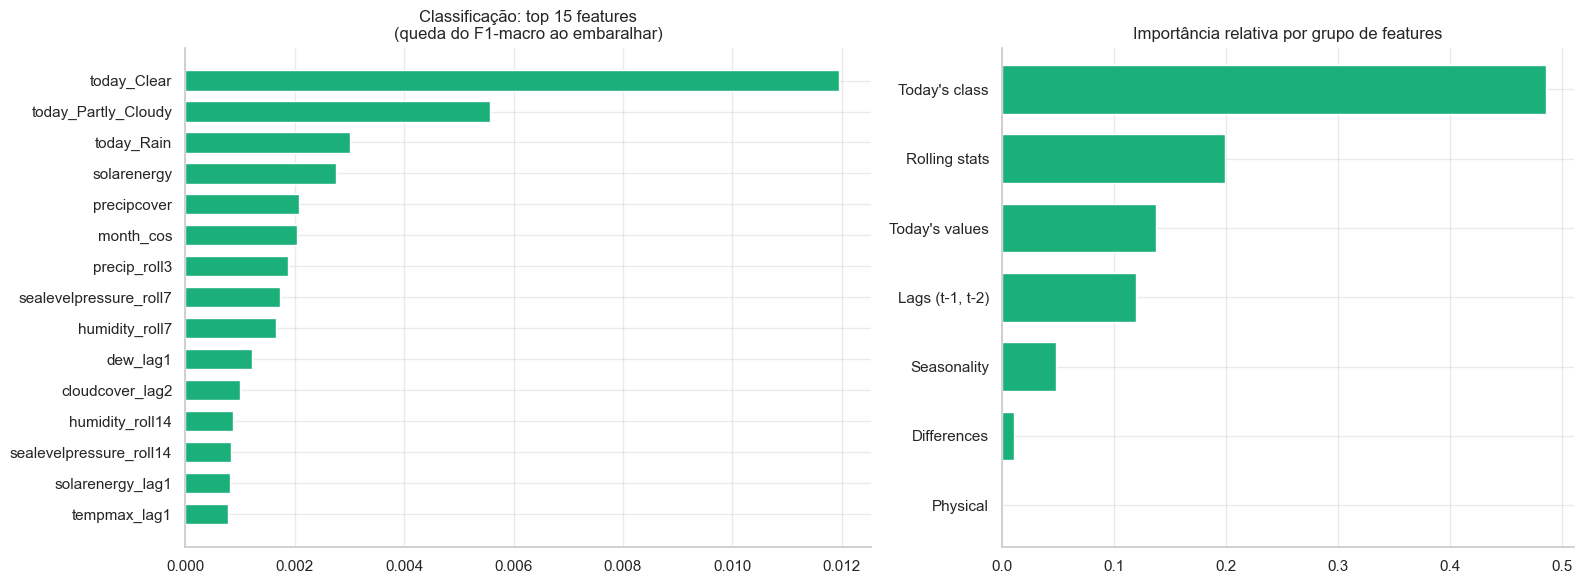

In [36]:
# 9.10 Importância das features na classificação (permutation, validação, F1-macro)
pi = permutation_importance(clf_tuned, X_val, y_val_c, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp_c = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})
top = imp_c.head(15)[::-1]
axes[0].barh(top.index, top.values, color=C_AQUA, height=0.65)
axes[0].set_title("Classificação: top 15 features\n(queda do F1-macro ao embaralhar)")
g = imp_c.clip(lower=0).groupby(imp_c.index.map(wu.feature_group)).sum()
(g / g.sum()).sort_values().plot.barh(ax=axes[1], color=C_AQUA, width=0.7)
axes[1].set_title("Importância relativa por grupo de features")
plt.tight_layout(); save_fig("clf_feature_importance"); plt.show()

**Interpretação.** O grupo mais importante é a **classe de hoje** (cerca de metade da importância), puxado por `today_Clear` e `today_Partly_Cloudy`,
seguido das **médias móveis** (chuva dos últimos 3 dias, pressão e umidade da última semana) e de **variáveis de hoje** (`solarenergy`, `precipcover`).
O modelo aprende essencialmente "o céu de amanhã ≈ o céu de hoje", com ajustes pela chuva e umidade recentes, pela pressão e pela estação
(`month_cos`) – o que explica por que ele fica tão perto da persistência. (Importância medida no Extra Trees ajustado, um dos membros do ensemble final.)

---
## 10. Resumo final dos resultados (teste 2024–2025)

In [37]:
# ---------------------------------------------------------------
# 10.1 Painel-resumo gerado automaticamente a partir dos resultados
# ---------------------------------------------------------------
print("=" * 78)
print(f" RESUMO – {LOCATION_NAME} | fonte: {DATA_SOURCE} | teste: alvos de 2024-01-01 a 2025-12-31")
print("=" * 78)
for target, (_, label) in REG_TARGETS.items():
    t = reg_test_table.loc[label]
    fk = [k for k in t.index if k.startswith("FINAL")][0]
    print(f"\n[Regressão] {label} de amanhã -> {fk}")
    print(f"   MAE  : {t.loc[fk, 'MAE']:.3f} °C  (persistência {t.loc['Persistence', 'MAE']:.3f} °C, "
          f"climatologia {t.loc['Climatology', 'MAE']:.3f} °C)")
    print(f"   RMSE : {t.loc[fk, 'RMSE']:.3f} °C | R² = {t.loc[fk, 'R2']:.3f} | r = {t.loc[fk, 'Pearson_r']:.3f}")
    print(f"   Redução do erro vs persistência: {1 - t.loc[fk, 'MAE'] / t.loc['Persistence', 'MAE']:.1%}")
c = clf_test_table
print(f"\n[Classificação] condição de amanhã -> {final_key}")
print(f"   F1-macro: {c.loc[final_key, 'F1_macro']:.3f}  (persistência {c.loc['Persistence', 'F1_macro']:.3f}, "
      f"majoritária {c.loc['Majority', 'F1_macro']:.3f})")
print(f"   Acurácia: {c.loc[final_key, 'Accuracy']:.3f}  (persistência {c.loc['Persistence', 'Accuracy']:.3f}, "
      f"majoritária {c.loc['Majority', 'Accuracy']:.3f})")
print("\nArquivos gerados: data/macao_openmeteo.csv, data/processed, figures/*.png, results/*.csv, models/*.joblib")

 RESUMO – Macau | fonte: Open-Meteo (ERA5) | teste: alvos de 2024-01-01 a 2025-12-31

[Regressão] Tmax de amanhã -> FINAL (Ensemble)
   MAE  : 1.220 °C  (persistência 1.510 °C, climatologia 2.139 °C)
   RMSE : 1.605 °C | R² = 0.884 | r = 0.942
   Redução do erro vs persistência: 19.2%

[Regressão] Tmin de amanhã -> FINAL (Ensemble)
   MAE  : 0.987 °C  (persistência 1.107 °C, climatologia 1.790 °C)
   RMSE : 1.382 °C | R² = 0.933 | r = 0.967
   Redução do erro vs persistência: 10.8%

[Classificação] condição de amanhã -> FINAL (Ensemble)
   F1-macro: 0.501  (persistência 0.489, majoritária 0.172)
   Acurácia: 0.606  (persistência 0.596, majoritária 0.524)

Arquivos gerados: data/macao_openmeteo.csv, data/processed, figures/*.png, results/*.csv, models/*.joblib


## 11. Discussão, limitações e trabalhos futuros

### Discussão
* **Por que os modelos venceram a persistência?** A persistência só "copia" o dia de hoje. Os modelos de ML combinam o estado atual com a
  **tendência** (lags, diferenças de temperatura e pressão), o **regime recente** (médias móveis) e a **época do ano** (seno/cosseno).
  Assim, eles "sabem", por exemplo, que um dia excepcionalmente quente em dezembro tende a voltar ao normal (*regressão à média*),
  e que pressão subindo rápido no inverno indica a chegada de uma frente fria.
* **Modelos lineares foram competitivos.** Grande parte da relação "temperatura de hoje → temperatura de amanhã" é aproximadamente linear:
  em Tmax, Ridge e LinearRegression ficam a 0,002 °C do melhor modelo (GradientBoosting) treinando milhares de vezes mais rápido. Isso mostra que **a engenharia de features
  importa mais que a escolha do algoritmo** – uma lição central do projeto.
* **A melhoria é praticamente relevante?** Em temperatura, sim: 0,1 a 0,3 °C a menos de erro médio (−11 a −19 %), estatisticamente significativo e
  **concentrado no inverno** (Tmax: −0,48 °C de MAE), quando ondas de frio afetam saúde, energia e agricultura. Em classificação de 4 classes,
  **não**: o ganho sobre a persistência (0,501 × 0,489) não é significativo; o valor prático está nas **probabilidades de chuva** (Brier −37 % vs climatologia).
* **Comparar muitos modelos valeu a pena; tuning ajudou pouco; ensemble ajudou um pouco.** O GradientBoosting e o Extra Trees, que só entraram na
  comparação ampla, foram os melhores da validação em Tmax e na classificação. O ganho real veio das **features** (lags, médias móveis, sazonalidade) e da **combinação de modelos**,
  não da busca de hiperparâmetros.
* **Classificação é muito mais difícil.** A precipitação tem baixa autocorrelação e depende de fenômenos de escala sinótica (frentes, tufões)
  que não são visíveis com dados de **um único ponto**. As classes intermediárias (*Partly Cloudy* × *Cloudy*) são as mais confundidas:
  a fronteira entre elas é um limiar arbitrário de cobertura de nuvens, então dias perto do limiar são quase "cara ou coroa".

### Limitações
* **Dados:** um único ponto de grade; o ERA5 é uma reanálise de ~25 km que suaviza extremos e superestima garoa;
  as classes dependem de limiares escolhidos por nós (1 mm, 30 %, 70 %).
* **Modelo:** não enxerga informação espacial (o que está acontecendo a montante – ex.: um tufão a 500 km) nem previsões numéricas;
  eventos raros (tufões, frentes fortes) têm poucos exemplos no treino.
* **Avaliação:** o teste cobre 2 anos; anos atípicos (El Niño/La Niña) podem mudar o desempenho. Também ocorre deriva climática
  (aquecimento) – o modelo treinado em 2014–2023 pode subestimar levemente temperaturas futuras.

### Trabalhos futuros
* **Mais dados/espaciais:** variáveis de estações vizinhas (Guangzhou, Hong Kong, Zhuhai) e índices climáticos (ENSO, monção).
* **Dados horários:** features intra‑diárias (pressão às 18h, tendência da tarde) e previsões para várias horas.
* **Modelos:** gradient boosting com previsões **probabilísticas** (quantis → intervalos de confiança), modelos sequenciais (LSTM/Temporal Fusion Transformer),
  *stacking* com meta‑modelo, e calibração das probabilidades de chuva.
* **Validação:** *walk‑forward* (re‑treinar a cada mês) para simular o uso operacional real.

### Impacto e uso responsável
Útil para planejamento cotidiano (energia, eventos, agricultura urbana, escolas), mas **não substitui** os avisos oficiais
dos **Serviços Meteorológicos e Geofísicos de Macau (SMG)** – especialmente para tufões e chuvas intensas, onde um falso "Clear" pode ter
consequências graves. Recomenda‑se sempre comunicar a **incerteza** (ex.: "erro típico de ±1 °C") e evitar a confiança cega no modelo.